### **Group Members**
| Student Name | Roll Number |
| :--- | :--- |
| **Noor ul Ain Amin** | **CS-052** |
| **Aaisha Jamil** | **CS-053** |
| **Syeda Maham Fatima** | **CS-054** |
| **Nawal Abid** | **CS-061** |
---

### **Project Architecture & Flowchart**
```
  Schedule File                               Environment File
        │                                             │
        ▼                                             ▼
┌──────────────────┐                         ┌──────────────────┐
│    CSP Solver    │                         │   Graph-Search   │
│  (Backtracking + │                         │   (BFS/GBFS/A*)  │
│  MRV, Deg, LCV)  │                         └─────────┬────────┘
└────────┬─────────┘                                   │
         │ Feasible Schedule                           │
         ▼                                             │
┌──────────────────────────────────────────────────────┴────────┐
│             Integration Module (`execute_schedule`)           │
│  - Sequence: Start @ C -> Di in Slot Order -> Return to C     │
│  - Step-by-Step Simulation & Marking Locations as CLEANED     │
│  - Full Journey Reporting & Final Cleaned Grid Visualization  │
└───────────────────────────────────────────────────────────────┘
```

## **1. Imports, Input Files & Upload**
This notebook works with **any number of Environment/Schedule pairs**. Upload all your files in one go; every Environment file is automatically paired with the Schedule file that carries the same name suffix (case and punctuation are ignored):

| Environment file | Schedule file | Paired because the suffix is... |
| :--- | :--- | :--- |
| `Environment.txt` | `Schedule.txt` | *(empty)* |
| `Environment_<name>.txt` | `Schedule_<name>.txt` | `<name>` |

- Upload **one** pair → every section shows the results of that one pair.
- Upload **two** pairs → every section shows the results of both, one block after the other, each headed by its own file names.
- Upload **more** pairs → one block per pair, in every section.
- If there is exactly one Environment and one Schedule file left without a name match, they are paired together; any other file without a partner is reported as *unpaired* and ignored.

Each block is headed `RUN i/N: <Environment file> + <Schedule file>` and every plot title carries the same file names.

In [57]:
import re
import math
import time
import heapq
import itertools
import os
import random
import statistics
from collections import deque
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import Normalize

# ----------------------------------------------------------------------------
# INPUT FILES: any number of (Environment, Schedule) pairs.
# Each pair becomes one "run"; every section below reports each run separately.
# ----------------------------------------------------------------------------
RUNS = []             # filled by the upload cell (Section 1)
UNPAIRED_FILES = []   # uploaded files that could not be paired


def _canonical_name(fname):
    """Colab renames a re-uploaded file to 'name (1).txt' -> restore 'name.txt'."""
    return re.sub(r"\s\(\d+\)(?=\.[^.]+$)", "", fname)


def _pair_key(fname, kind):
    """Name suffix used for pairing (case/punctuation ignored):
    'Environment_Sample.txt' -> 'sample', 'Schedule._sample.txt' -> 'sample', 'Environment.txt' -> ''."""
    stem = os.path.splitext(_canonical_name(fname))[0].lower().replace(kind, "", 1)
    return re.sub(r"[^a-z0-9]", "", stem)


def pair_input_files(filenames):
    """Pairs Environment files with Schedule files by name suffix.
    Returns (pairs, unpaired_environment_files, unpaired_schedule_files)."""
    envs = sorted((f for f in filenames if "environment" in f.lower()), key=str.lower)
    scheds = sorted((f for f in filenames if "schedule" in f.lower()), key=str.lower)

    sched_by_key = {}
    for s in scheds:
        sched_by_key.setdefault(_pair_key(s, "schedule"), []).append(s)

    pairs, lone_envs = [], []
    for e in envs:
        candidates = sched_by_key.get(_pair_key(e, "environment"))
        if candidates:
            pairs.append((e, candidates.pop(0)))
        else:
            lone_envs.append(e)
    lone_scheds = [s for group in sched_by_key.values() for s in group]

    # Exactly one leftover Environment and one leftover Schedule -> they belong together
    if len(lone_envs) == 1 and len(lone_scheds) == 1:
        pairs.append((lone_envs[0], lone_scheds[0]))
        lone_envs, lone_scheds = [], []

    pairs.sort(key=lambda p: p[0].lower())
    return pairs, lone_envs, lone_scheds


def build_runs(filenames):
    """Fills RUNS (one dict per Environment+Schedule pair) and prints the pairing."""
    pairs, lone_envs, lone_scheds = pair_input_files(filenames)
    RUNS.clear()
    for i, (env_file, sched_file) in enumerate(pairs, 1):
        RUNS.append({"index": i, "env_file": env_file, "sched_file": sched_file,
                     "label": f"{env_file} + {sched_file}",
                     "grid": None, "env_ok": False, "env_errors": [],
                     "csp_ready": False, "sched_ok": False, "sched_errors": [],
                     "solution": None, "csp_status": "NOT_RUN", "order": None, "exec": {}})
    UNPAIRED_FILES[:] = lone_envs + lone_scheds

    print(f"Detected {len(RUNS)} Environment/Schedule pair(s):")
    for run in RUNS:
        print(f"  RUN {run['index']}: {run['env_file']}  <->  {run['sched_file']}")
    if UNPAIRED_FILES:
        print("\n[WARNING] Unpaired file(s) (ignored - no matching Environment/Schedule partner):")
        for f in UNPAIRED_FILES:
            print(f"  - {f}")
    if not RUNS:
        print("\n[NO INPUT] No Environment/Schedule pair found. Re-run the upload cell and select "
              "at least one Environment file and its Schedule file.")


def iter_runs():
    """The runs every section loops over."""
    if not RUNS:
        print("[NO INPUT] No Environment/Schedule pair was uploaded - re-run the upload cell in Section 1.")
    return RUNS


def run_header(run, title=""):
    print("\n" + "#" * 80)
    suffix = f"  |  {title}" if title else ""
    print(f"# RUN {run['index']}/{len(RUNS)}: {run['env_file']} + {run['sched_file']}{suffix}")
    print("#" * 80)


def need_valid_env(run, what):
    """True if the run's environment loaded and is valid; otherwise prints why `what` is skipped."""
    if run.get("grid") is None or not run.get("env_ok"):
        print(f"[SKIPPED] {what} needs a valid environment, but '{run['env_file']}' is not valid:")
        for err in (run.get("env_errors") or ["the environment could not be loaded"]):
            print(f"  - {err}")
        return False
    return True

In [58]:
def discover_local_files():
    """Outside Colab: Environment/Schedule .txt files in the working directory."""
    return [f for f in os.listdir(".")
            if f.lower().endswith(".txt") and ("environment" in f.lower() or "schedule" in f.lower())]


def upload_input_files():
    """Colab: upload ALL Environment and Schedule files at once (any number of pairs).
    Only the files uploaded in THIS run of the cell are used.
    Outside Colab: uses the Environment/Schedule .txt files found next to the notebook."""
    try:
        from google.colab import files as colab_files
    except ImportError:
        colab_files = None

    if colab_files is None:
        names = discover_local_files()
        print(f"Not running in Google Colab - using the .txt files found in {os.getcwd()}\n")
    else:
        print("Select ALL your Environment and Schedule .txt files (one or more pairs) and upload them together.")
        uploaded = colab_files.upload()
        names = []
        for fname in uploaded:
            canon = _canonical_name(fname)
            if canon != fname:
                os.replace(fname, canon)       # 'Environment (1).txt' -> 'Environment.txt'
            names.append(canon)

    build_runs(sorted(set(n for n in names if n.lower().endswith(".txt"))))


upload_input_files()

Select ALL your Environment and Schedule .txt files (one or more pairs) and upload them together.


Saving Schedule_Sample.txt to Schedule_Sample (1).txt
Saving Environment_Sample.txt to Environment_Sample (1).txt
Saving Schedule_Error.txt to Schedule_Error (1).txt
Saving Environment_Error.txt to Environment_Error (1).txt
Saving Schedule.txt to Schedule (1).txt
Saving Environment.txt to Environment (1).txt
Detected 3 Environment/Schedule pair(s):
  RUN 1: Environment.txt  <->  Schedule.txt
  RUN 2: Environment_Error.txt  <->  Schedule_Error.txt
  RUN 3: Environment_Sample.txt  <->  Schedule_Sample.txt


## **2. Environment Loading & Coordinate Parsing**

The robot environment is loaded from every uploaded Environment file, which must follow this format:
1. Line 1: Grid dimensions as `rows,cols`
2. Line 2: Number of obstacles
3. Line 3: Obstacle coordinates as `(row, col)` tuples
4. Line 4: Number of dirty locations
5. Line 5: Dirty location coordinates as `(row, col)` tuples (first is D1, second D2, etc.)
6. Line 6: Coordinate of the charging station as a `(row, col)` tuple

**Robust loader.** The parser is tolerant of small layout differences so that a slightly different grader file does not crash it:
- obstacle (or dirty) coordinates may be spread over **several lines**;
- an **empty / missing charging-station line** is reported by the validator as a clear error instead of raising a `TypeError`;
- malformed headers raise a `ValueError` that explains which line is wrong.

> **Important:** **Exactly one** charging station is required. The parser records how many charging coordinates the file declares (`raw_charging_count`) so that `validate_environment` can enforce this rule.

In [59]:
COORD_RE = re.compile(r"\(\s*(-?\d+)\s*,\s*(-?\d+)\s*\)")


def parse_coordinates(text):
    """Extracts every '(row, col)' pair from a string -> list of (row, col) integer tuples.
    Returns [] for an empty line or an empty tuple '()'."""
    return [(int(r), int(c)) for r, c in COORD_RE.findall(text)]


def _is_int_line(text):
    return re.fullmatch(r"-?\d+", text.strip()) is not None


def parse_environment_text(text):
    """Parses the content of an Environment file (see Section 2 for the layout)."""
    lines = [ln.strip() for ln in text.splitlines() if ln.strip()]
    if len(lines) < 3:
        raise ValueError("Environment file is too short: expected grid size, obstacle count, "
                         "obstacle list, dirty count, dirty list and charging station.")

    # Line 1: grid dimensions
    dims = re.findall(r"-?\d+", lines[0])
    if len(dims) != 2:
        raise ValueError(f"Line 1 must contain 'rows,cols' but found: '{lines[0]}'.")
    rows, cols = int(dims[0]), int(dims[1])

    # Line 2: obstacle count
    if not _is_int_line(lines[1]):
        raise ValueError(f"Line 2 must be the number of obstacles but found: '{lines[1]}'.")
    obstacle_count = int(lines[1])

    # Obstacle coordinate lines (any number of lines) up to the dirty-count line
    idx = 2
    obstacle_list = []
    while idx < len(lines) and not _is_int_line(lines[idx]):
        obstacle_list.extend(parse_coordinates(lines[idx]))
        idx += 1
    if idx >= len(lines):
        raise ValueError("Could not find the 'number of dirty locations' line after the obstacle list.")
    dirty_count = int(lines[idx])
    idx += 1

    # Remaining coordinate lines: the LAST coordinate line is the charging station,
    # everything before it is the dirty-location list.
    coord_lines = [parse_coordinates(ln) for ln in lines[idx:]]
    coord_lines = [cl for cl in coord_lines if cl]
    if len(coord_lines) >= 2:
        raw_charging = coord_lines[-1]
        dirty_locations = [pt for cl in coord_lines[:-1] for pt in cl]
    elif len(coord_lines) == 1:           # charging-station line is empty / missing
        raw_charging = []
        dirty_locations = coord_lines[0]
    else:
        raw_charging, dirty_locations = [], []

    return {
        "rows": rows,
        "cols": cols,
        "obstacles": set(obstacle_list),
        "dirty_locations": dirty_locations,
        "charging_station": raw_charging[0] if raw_charging else None,
        "declared_obstacle_count": obstacle_count,
        "declared_dirty_count": dirty_count,
        "raw_charging_count": len(raw_charging),
        "raw_obstacle_count": len(obstacle_list),
    }


def load_environment(filename):
    """Loads the environment grid from the specified text file."""
    if not os.path.exists(filename):
        raise FileNotFoundError(f"'{filename}' not found. Run the upload cell in Section 1 "
                                f"or place the file in {os.getcwd()}.")
    with open(filename, "r") as file:
        return parse_environment_text(file.read())

## **3. Environment Functions & Heuristic Mathematical Formulation**

### **Required Search Functions**
- `get_successors(state, grid)`: Returns valid neighbor states reachable by actions `UP`, `DOWN`, `LEFT`, `RIGHT` with unit cost = 1.
- `goal_test(state, goal_state)`: Checks whether `state == goal_state`.
- `path_cost(path)`: Calculates total path cost (number of transitions = `len(path) - 1`). Handles empty paths and single-cell paths.
- `heuristic(state, goal_state)`: Estimates remaining cost using **Manhattan Distance**.

---

### **Theoretical Justification of Manhattan Distance Heuristic**
The Manhattan Distance between state $n = (r_n, c_n)$ and goal state $g = (r_g, c_g)$ is:
$$h(n) = |r_n - r_g| + |c_n - c_g|$$

#### **1. Appropriateness for 4-Directional Movement**
In this grid environment, movement is strictly restricted to orthogonal directions (Up, Down, Left, Right) with step cost $c = 1$. Diagonal movements are prohibited. Therefore, the minimum possible distance between any two cells in an unconstrained grid is along horizontal and vertical grid lines, exactly modeled by Manhattan distance ($L_1$ norm). Euclidean distance ($L_2$) would underestimate actual orthogonal moves, while Chebyshev distance ($L_\infty$) assumes diagonal moves.

#### **2. Proof of Admissibility ($h(n) \le h^*(n)$)**
An admissible heuristic never overestimates the true minimal cost $h^*(n)$ to reach the goal.
- In the absence of obstacles, the shortest orthogonal path between $(r_n, c_n)$ and $(r_g, c_g)$ requires exactly $|r_n - r_g|$ vertical steps and $|c_n - c_g|$ horizontal steps.
- Since each step has cost 1, the theoretical minimum cost is $h(n)$.
- The presence of obstacles can only force the robot to take detour paths, so the true shortest path $h^*(n)$ in the presence of obstacles satisfies $h^*(n) \ge h(n)$.
- Therefore, $h(n) \le h^*(n)$ for all nodes $n$, proving **admissibility**.

#### **3. Proof of Consistency (Monotonicity)**
A heuristic is consistent if for every node $n$ and every successor $n'$ generated by action $a$:
$$h(n) \le c(n, a, n') + h(n')$$
- Any single valid action $a \in \{\text{UP, DOWN, LEFT, RIGHT}\}$ moves the robot to an adjacent cell, so $|r_n - r_{n'}| + |c_n - c_{n'}| = 1$, and $c(n, a, n') = 1$.
- By the reverse triangle inequality:
  $$|h(n) - h(n')| = \big|(|r_n - r_g| + |c_n - c_g|) - (|r_{n'} - r_g| + |c_{n'} - c_g|)\big| \le |r_n - r_{n'}| + |c_n - c_{n'}| = 1$$
- Hence, $h(n) - h(n') \le 1 = c(n, a, n') \implies h(n) \le c(n, a, n') + h(n')$.
- **Significance:** Because $h(n)$ is consistent, A* search using graph-search will find the optimal path without ever needing to re-open closed nodes.

In [60]:
def get_successors(state, grid):
    """Finds all valid successor states reachable via UP, DOWN, LEFT, RIGHT.
    Returns: list of (next_state, action, step_cost)."""
    row, col = state
    moves = [
        (-1, 0, "UP"),
        (1, 0, "DOWN"),
        (0, -1, "LEFT"),
        (0, 1, "RIGHT")
    ]
    successors = []
    for dr, dc, action in moves:
        new_row = row + dr
        new_col = col + dc
        next_state = (new_row, new_col)
        if (
            0 <= new_row < grid["rows"]
            and 0 <= new_col < grid["cols"]
            and next_state not in grid["obstacles"]
        ):
            successors.append((next_state, action, 1))
    return successors


def goal_test(state, goal_state):
    """Checks whether the current state matches the goal state."""
    return state == goal_state


def path_cost(path):
    """Calculates the total path cost (number of movements).
    An empty path or a single-state path has cost 0."""
    if not path or len(path) <= 1:
        return 0
    return len(path) - 1


def heuristic(state, goal_state):
    """Calculates the Manhattan distance heuristic between state and goal_state:
    h(n) = |row_n - row_goal| + |col_n - col_goal|
    This heuristic is admissible and consistent for 4-directional unit-cost grid movement."""
    return abs(state[0] - goal_state[0]) + abs(state[1] - goal_state[1])

## **4. Environment Validation**

1. **Grid size:** At least $8 \times 8$ cells.
2. **Obstacles:** At least 6 obstacle cells.
3. **Dirty locations:** At least 4 distinct dirty locations.
4. **Charging station:** Exactly one charging station.
5. **No overlap:** Charging station, dirty locations, and obstacles must occupy distinct cells.
6. **Reachability:** Every dirty location must be reachable from the charging station.

In [61]:
def is_reachable(start, goal, grid):
    """Breadth-first connectivity check to verify reachability between two states."""
    if start == goal:
        return True
    queue = deque([start])
    visited = {start}
    while queue:
        current = queue.popleft()
        if current == goal:
            return True
        for next_state, action, cost in get_successors(current, grid):
            if next_state not in visited:
                visited.add(next_state)
                queue.append(next_state)
    return False


def validate_environment(grid, verbose=True):
    """Validates the environment against all rules specified in Handout Section 4.
    Never raises on bad data (e.g. a missing charging station) - it reports it.
    Returns (is_valid, list_of_errors)."""
    rows, cols = grid["rows"], grid["cols"]
    obstacles = grid["obstacles"]
    dirty = grid["dirty_locations"]
    charging = grid["charging_station"]
    in_bounds = lambda p: 0 <= p[0] < rows and 0 <= p[1] < cols

    errors = []

    # 1. Grid size
    if rows < 8 or cols < 8:
        errors.append(f"Grid size ({rows}x{cols}) must be at least 8x8.")

    # 2. Obstacles count
    if len(obstacles) < 6:
        errors.append(f"At least 6 obstacles required, found {len(obstacles)}.")

    # 3. Dirty locations count
    if len(dirty) < 4:
        errors.append(f"At least 4 dirty locations required, found {len(dirty)}.")

    # 4. Duplicate dirty locations
    if len(dirty) != len(set(dirty)):
        errors.append("Duplicate dirty locations found in file.")

    # 5. Declared counts consistency
    if len(obstacles) != grid.get("declared_obstacle_count", len(obstacles)):
        errors.append(f"Declared obstacle count ({grid.get('declared_obstacle_count')}) != "
                      f"actual distinct obstacles ({len(obstacles)}).")
    if len(dirty) != grid.get("declared_dirty_count", len(dirty)):
        errors.append(f"Declared dirty count ({grid.get('declared_dirty_count')}) != "
                      f"actual count ({len(dirty)}).")

    # 6. Exactly one charging station
    if charging is None:
        errors.append("No charging station found (the charging-station line is empty or missing).")
    elif grid.get("raw_charging_count", 1) != 1:
        errors.append(f"Exactly one charging station required, found {grid.get('raw_charging_count')}.")

    # 7. Coordinate bounds
    all_positions = set(obstacles) | set(dirty)
    if charging is not None:
        all_positions.add(charging)
    for pos in sorted(all_positions):
        if not in_bounds(pos):
            errors.append(f"Coordinate {pos} is outside grid boundaries.")

    # 8. Overlaps
    if obstacles.intersection(set(dirty)):
        errors.append(f"Obstacle overlaps dirty location: {sorted(obstacles.intersection(set(dirty)))}.")
    if charging is not None and charging in obstacles:
        errors.append(f"Charging station {charging} overlaps an obstacle.")
    if charging is not None and charging in set(dirty):
        errors.append(f"Charging station {charging} overlaps a dirty location.")

    # 9. Reachability (only meaningful when the charging station itself is a legal free cell)
    if charging is not None and in_bounds(charging) and charging not in obstacles:
        for loc in dirty:
            if not in_bounds(loc) or loc in obstacles:
                continue                        # already reported above
            if not is_reachable(charging, loc, grid):
                errors.append(f"Dirty location {loc} is unreachable from charging station {charging}.")

    is_valid = len(errors) == 0
    if verbose:
        if not is_valid:
            print("[WARNING] Environment validation detected issues:")
            for err in errors:
                print(f"  - {err}")
        else:
            print("[SUCCESS] All environment validation checks passed successfully!")
    return is_valid, errors

## **5. Environment Visualization**
Visualizes the grid showing the charging station (C), obstacles (X), and labeled dirty locations (D1, D2, ...).


################################################################################
# RUN 1/3: Environment.txt + Schedule.txt  |  Environment
################################################################################
Environment configuration (Environment.txt):
  Grid Dimensions  : 8 x 8
  Obstacles (8)   : [(0, 0), (0, 5), (2, 4), (3, 2), (3, 6), (6, 1), (6, 5), (7, 3)]
  Dirty Locations (4): D1=(5, 3), D2=(4, 4), D3=(1, 2), D4=(6, 7)
  Charging Station : (0, 7)
[SUCCESS] All environment validation checks passed successfully!


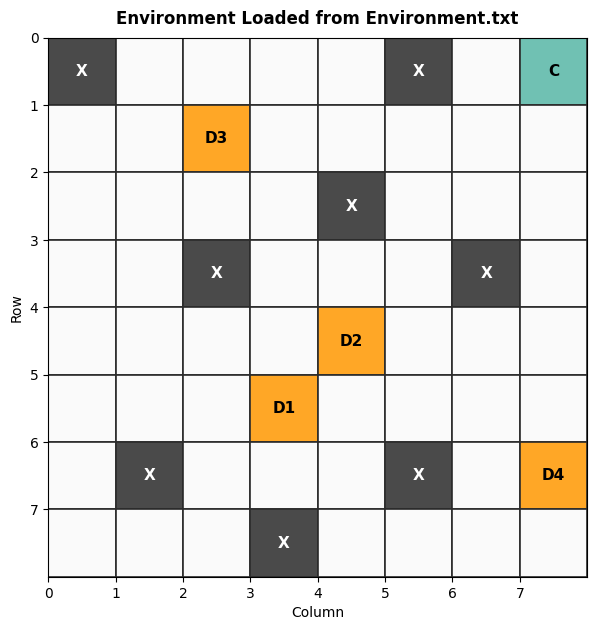


################################################################################
# RUN 2/3: Environment_Error.txt + Schedule_Error.txt  |  Environment
################################################################################
Environment configuration (Environment_Error.txt):
  Grid Dimensions  : 8 x 8
  Obstacles (11)   : [(0, 0), (0, 5), (2, 4), (3, 2), (3, 6), (5, 7), (6, 1), (6, 5), (6, 6), (7, 3), (7, 7)]
  Dirty Locations (4): D1=(5, 3), D2=(4, 4), D3=(1, 2), D4=(6, 7)
  Charging Station : (0, 7)
[WARNING] Environment validation detected issues:
  - Dirty location (6, 7) is unreachable from charging station (0, 7).


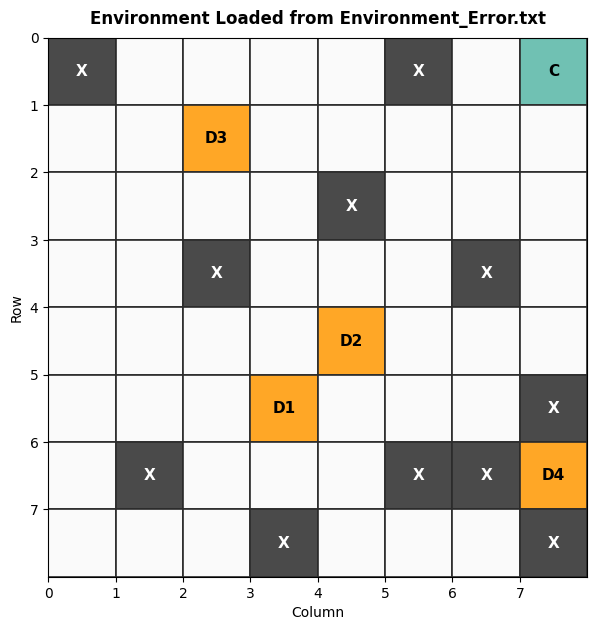


################################################################################
# RUN 3/3: Environment_Sample.txt + Schedule_Sample.txt  |  Environment
################################################################################
Environment configuration (Environment_Sample.txt):
  Grid Dimensions  : 8 x 8
  Obstacles (6)   : [(1, 3), (2, 3), (3, 3), (4, 3), (5, 3), (6, 3)]
  Dirty Locations (4): D1=(0, 7), D2=(3, 7), D3=(7, 7), D4=(7, 0)
  Charging Station : (0, 0)
[SUCCESS] All environment validation checks passed successfully!


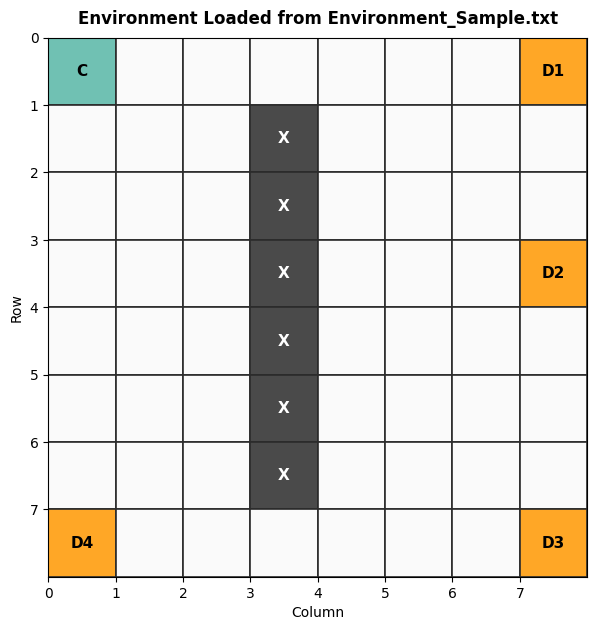

In [62]:
def print_environment_config(grid, source=""):
    """Prints the environment configuration (needed for the test-run screenshots)."""
    print(f"Environment configuration{(' (' + source + ')') if source else ''}:")
    print(f"  Grid Dimensions  : {grid['rows']} x {grid['cols']}")
    print(f"  Obstacles ({len(grid['obstacles'])})   : {sorted(grid['obstacles'])}")
    labelled = [f"D{i + 1}={c}" for i, c in enumerate(grid['dirty_locations'])]
    print(f"  Dirty Locations ({len(grid['dirty_locations'])}): {', '.join(labelled)}")
    print(f"  Charging Station : {grid['charging_station']}")


def display_grid(grid, title="Vacuum Cleaning Robot Environment"):
    """Renders the 2D grid environment."""
    rows = grid["rows"]
    cols = grid["cols"]
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)
    ax.set_aspect("equal")

    for r in range(rows):
        for c in range(cols):
            color, label, tc = "#FAFAFA", "", "black"
            if (r, c) in grid["obstacles"]:
                color, label, tc = "#4A4A4A", "X", "white"
            elif (r, c) in grid["dirty_locations"]:
                color = "#FFA726"
                idx = grid["dirty_locations"].index((r, c)) + 1
                label = f"D{idx}"
                tc = "black"
            elif (r, c) == grid["charging_station"]:
                color, label, tc = "#70C1B3", "C", "black"

            rect = patches.Rectangle((c, r), 1, 1, facecolor=color, edgecolor="#2B2B2B", linewidth=1.2)
            ax.add_patch(rect)
            if label:
                ax.text(c + 0.5, r + 0.5, label, ha="center", va="center", fontsize=11, fontweight="bold", color=tc)

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    plt.grid(False)
    plt.show()



def load_and_check_environment(run):
    """Loads, prints, validates and displays one run's environment (results stored in `run`)."""
    run_header(run, "Environment")
    try:
        grid = load_environment(run["env_file"])
    except Exception as exc:
        run["grid"], run["env_ok"] = None, False
        run["env_errors"] = [f"{type(exc).__name__}: {exc}"]
        print(f"[ERROR] Could not load {run['env_file']}: {run['env_errors'][0]}")
        return
    run["grid"] = grid
    print_environment_config(grid, run["env_file"])
    run["env_ok"], run["env_errors"] = validate_environment(grid)
    display_grid(grid, title=f"Environment Loaded from {run['env_file']}")


for run in iter_runs():
    load_and_check_environment(run)

## **6. Graph-Based Search Algorithms**

**Three** algorithms:
1. **Breadth-First Search (BFS):** Uninformed search expanding nodes layer-by-layer (FIFO queue). Guarantees optimal path length in unit-cost graphs.
2. **Greedy Best-First Search (GBFS):** Informed search expanding nodes based solely on $h(n)$ (priority queue). Fast, but not guaranteed to find an optimal path.
3. **A\* Search:** Informed search expanding nodes based on $f(n) = g(n) + h(n)$. Guaranteed to be complete and strictly optimal because Manhattan distance is admissible and consistent.

All algorithms implement the standardized search signature:
`search(grid, start, goal, algorithm) -> (path, cost, nodes_expanded)`

> **Definition of `nodes_expanded`.** The number of nodes removed from the frontier and examined by the goal test. The goal node itself is counted when it is removed, so a non-trivial search always reports at least 1. (A* does not count stale duplicate frontier entries that are skipped because the node is already closed.) The trivial case `start == goal` returns immediately without running any search, so it reports **0** expansions. An optional `explored` list can be passed to `search` to record the expansion order (used only for the visualisations in Section 8.1).

In [63]:
def _reconstruct_path(parent, goal):
    path, node = [], goal
    while node is not None:
        path.append(node)
        node = parent[node]
    path.reverse()
    return path


def breadth_first_search(start, goal, grid, explored=None):
    """Breadth-First Search (Uninformed). Returns (path, cost, nodes_expanded)."""
    if start == goal:
        return [start], 0, 0
    frontier = deque([start])
    parent = {start: None}
    nodes_expanded = 0

    while frontier:
        current = frontier.popleft()
        nodes_expanded += 1
        if explored is not None:
            explored.append(current)
        if current == goal:
            path = _reconstruct_path(parent, goal)
            return path, len(path) - 1, nodes_expanded

        for next_state, action, step_cost in get_successors(current, grid):
            if next_state not in parent:
                parent[next_state] = current
                frontier.append(next_state)

    return None, float("inf"), nodes_expanded


def greedy_best_first_search(start, goal, grid, explored=None):
    """Greedy Best-First Search (Informed: f(n) = h(n)). Returns (path, cost, nodes_expanded)."""
    if start == goal:
        return [start], 0, 0
    counter = itertools.count()
    frontier = [(heuristic(start, goal), next(counter), start)]
    parent = {start: None}
    nodes_expanded = 0

    while frontier:
        h, _, current = heapq.heappop(frontier)
        nodes_expanded += 1
        if explored is not None:
            explored.append(current)
        if current == goal:
            path = _reconstruct_path(parent, goal)
            return path, len(path) - 1, nodes_expanded

        for next_state, action, step_cost in get_successors(current, grid):
            if next_state not in parent:
                parent[next_state] = current
                heapq.heappush(frontier, (heuristic(next_state, goal), next(counter), next_state))

    return None, float("inf"), nodes_expanded


def A_star_search(start, goal, grid, explored=None):
    """A* Search (Informed: f(n) = g(n) + h(n)). Returns (path, cost, nodes_expanded)."""
    if start == goal:
        return [start], 0, 0
    counter = itertools.count()
    g_score = {start: 0}
    frontier = [(heuristic(start, goal), next(counter), start)]
    parent = {start: None}
    nodes_expanded = 0
    closed_set = set()

    while frontier:
        f, _, current = heapq.heappop(frontier)
        if current in closed_set:
            continue
        closed_set.add(current)
        nodes_expanded += 1
        if explored is not None:
            explored.append(current)

        if current == goal:
            path = _reconstruct_path(parent, goal)
            return path, len(path) - 1, nodes_expanded

        for next_state, action, step_cost in get_successors(current, grid):
            tentative_g = g_score[current] + step_cost
            if next_state not in g_score or tentative_g < g_score[next_state]:
                g_score[next_state] = tentative_g
                parent[next_state] = current
                f = tentative_g + heuristic(next_state, goal)
                heapq.heappush(frontier, (f, next(counter), next_state))

    return None, float("inf"), nodes_expanded


ALGORITHMS = {
    "BFS": breadth_first_search,
    "GBFS": greedy_best_first_search,
    "A*": A_star_search
}
ALGO_NAMES = ["BFS", "GBFS", "A*"]


def search(grid, start, goal, algorithm="A*", explored=None):
    """Dispatches to the specified search algorithm.
    Returns: (path, cost, nodes_expanded).  `explored` (optional list) records expansion order."""
    name = algorithm.upper().strip()
    if name not in ALGORITHMS:
        raise ValueError(f"Unknown algorithm '{algorithm}'. Must be BFS, GBFS, or A*.")
    return ALGORITHMS[name](start, goal, grid, explored=explored)

## **7. Search Testing: All Goals, Round-Trips & Edge Cases**
Every algorithm solves the start-to-goal pairs and handles edge cases properly:
- **Start == Goal:** must return `[start]`, cost 0, and 0 expansions.
- **Unreachable goal:** the goal is a **free (non-obstacle) cell that is completely walled in** by obstacles, so it is genuinely enclosed rather than simply being an obstacle itself. The search must return `path = None` and cost `inf`.

In [64]:
def make_enclosed_goal_grid(grid):
    """Builds a copy of `grid` in which one FREE cell (not an obstacle, not C, not a dirty
    location) is completely enclosed by obstacles. Returns (blocked_grid, enclosed_goal, walls)."""
    start = grid["charging_station"]
    protected = set(grid["dirty_locations"]) | {start}
    rows, cols = grid["rows"], grid["cols"]

    def neighbours(cell):
        r, c = cell
        return [(r + dr, c + dc) for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1))
                if 0 <= r + dr < rows and 0 <= c + dc < cols]

    # Prefer cells far from the start (corners first, then everything else)
    cells = sorted(((r, c) for r in range(rows) for c in range(cols)),
                   key=lambda p: -(abs(p[0] - start[0]) + abs(p[1] - start[1])))
    for cell in cells:
        if cell in grid["obstacles"] or cell in protected:
            continue
        nbrs = neighbours(cell)
        if any(n in protected for n in nbrs):
            continue
        blocked = dict(grid)
        blocked["obstacles"] = set(grid["obstacles"]) | set(nbrs)
        if not is_reachable(start, cell, blocked):
            return blocked, cell, sorted(set(nbrs) - set(grid["obstacles"]))
    return None, None, []


def run_edge_cases(grid, algorithm):
    """Tests start == goal and a genuinely enclosed (free) unreachable destination."""
    start = grid["charging_station"]
    # Edge Case 1: Start equals Goal
    p1, c1, exp1 = search(grid, start, start, algorithm)
    print(f"[{algorithm}] Start == Goal: Path={p1}, Cost={c1}, Expanded={exp1} -> "
          f"{'PASS' if c1 == 0 and p1 == [start] and exp1 == 0 else 'FAIL'}")

    # Edge Case 2: Unreachable destination = free cell enclosed by obstacles
    blocked_grid, enclosed_goal, walls = make_enclosed_goal_grid(grid)
    if blocked_grid is None:
        print(f"[{algorithm}] Unreachable Goal: could not construct an enclosed free cell -> SKIPPED")
        return
    p2, c2, exp2 = search(blocked_grid, start, enclosed_goal, algorithm)
    print(f"[{algorithm}] Unreachable Goal {enclosed_goal} (free cell, new walls at {walls}): "
          f"Path={p2}, Cost={c2}, Expanded={exp2} -> {'PASS' if p2 is None else 'FAIL'}")



for run in iter_runs():
    run_header(run, "Search testing")
    if not need_valid_env(run, "Search testing"):
        continue
    grid = run["grid"]
    start = grid["charging_station"]
    for algo in ALGO_NAMES:
        print(f"--- Testing {algo} ---")
        for i, goal in enumerate(grid["dirty_locations"]):
            path, cost, exp = search(grid, start, goal, algo)
            print(f" C {start} -> D{i+1} {goal} | Cost: {cost} | Expanded: {exp} | Path: {path}")
        run_edge_cases(grid, algo)
        print()


################################################################################
# RUN 1/3: Environment.txt + Schedule.txt  |  Search testing
################################################################################
--- Testing BFS ---
 C (0, 7) -> D1 (5, 3) | Cost: 9 | Expanded: 40 | Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (5, 6), (5, 5), (5, 4), (5, 3)]
 C (0, 7) -> D2 (4, 4) | Cost: 7 | Expanded: 27 | Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (4, 6), (4, 5), (4, 4)]
 C (0, 7) -> D3 (1, 2) | Cost: 6 | Expanded: 23 | Path: [(0, 7), (1, 7), (1, 6), (1, 5), (1, 4), (1, 3), (1, 2)]
 C (0, 7) -> D4 (6, 7) | Cost: 6 | Expanded: 17 | Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7)]
[BFS] Start == Goal: Path=[(0, 7)], Cost=0, Expanded=0 -> PASS
[BFS] Unreachable Goal (7, 0) (free cell, new walls at [(6, 0), (7, 1)]): Path=None, Cost=inf, Expanded=53 -> PASS

--- Testing GBFS ---
 C (0, 7) -> D1 (5, 3) | Cost: 9 | Expanded: 10 | Path: [(0, 7), (1, 7),

## **8. Comparative Analysis of Search Algorithms**

Behavioural comparison, Performance comparison, Path cost, Nodes expanded, Runtime and optimality, supported by tables and charts.

---

### **8.1 Behavioural Comparison**

| Metric / Dimension | Breadth-First Search (BFS) | Greedy Best-First Search (GBFS) | A* Search |
| :--- | :--- | :--- | :--- |
| **Strategy Type** | Uninformed (blind) | Informed (heuristic-only) | Informed (cost + heuristic) |
| **Evaluation Function** | $f(n) = g(n)$ (depth) | $f(n) = h(n)$ (Manhattan distance) | $f(n) = g(n) + h(n)$ |
| **Frontier Structure** | FIFO Queue (`deque`) | Priority Queue (`heapq`) | Priority Queue (`heapq`) |
| **Completeness** | **Yes** (on finite graphs) | **Yes** (with visited set) | **Yes** (on finite graphs) |
| **Optimality** | **Yes** (for unit step costs $c=1$) | **No** (*can* choose a detour) | **Yes** (admissible + consistent $h$) |
| **Search Behavior** | Expands in concentric rings blindly in all 4 directions | Drives straight toward the goal; can be lured into dead-end pockets | Guides exploration toward the goal while honouring the path cost already paid |
| **Explored Nodes** | **Highest** (expands the entire wavefront) | Often the lowest when the straight line is open; erratic near traps | Far fewer than BFS (measured in 8.2) |
| **Runtime** | Highest per query (most nodes) | Low per query | Low per query; slightly more bookkeeping per node than GBFS (`g`-scores) |

---

> The *Runtime* row is qualitative here; the exact measured microseconds per query appear in the tables and charts of Section 8.2.

---

### **8.1.1 Behavioural visualization on every uploaded environment (one figure per run)**
The three panels below run the three algorithms on the **same** start/goal pair (charging station $\to$ the farthest dirty location). Blue shading shows the **order of expansion** (light = early, dark = late); the red line is the returned path.

### **8.1.2 GBFS and optimality**
 GBFS ranks nodes only by h(n), so it *can* return a longer path than BFS and A*. How often this happens is **measured**: the optimal-path rate on each uploaded environment (8.2.2).


################################################################################
# RUN 1/3: Environment.txt + Schedule.txt  |  8.1.1 Behavioural visualisation
################################################################################


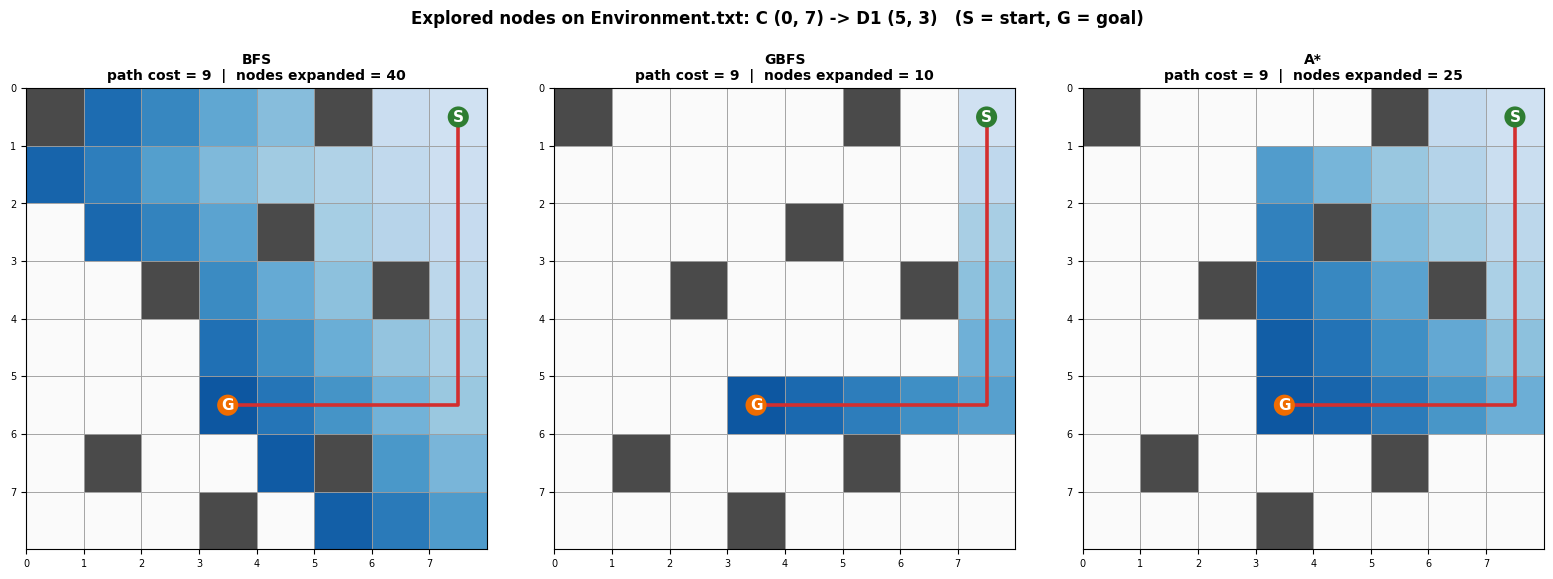

Nodes expanded for C -> D1:  BFS: 40  |  GBFS: 10  |  A*: 25
Path cost for C -> D1:       BFS: 9  |  GBFS: 9  |  A*: 9

################################################################################
# RUN 2/3: Environment_Error.txt + Schedule_Error.txt  |  8.1.1 Behavioural visualisation
################################################################################
[SKIPPED] Behavioural visualisation needs a valid environment, but 'Environment_Error.txt' is not valid:
  - Dirty location (6, 7) is unreachable from charging station (0, 7).

################################################################################
# RUN 3/3: Environment_Sample.txt + Schedule_Sample.txt  |  8.1.1 Behavioural visualisation
################################################################################


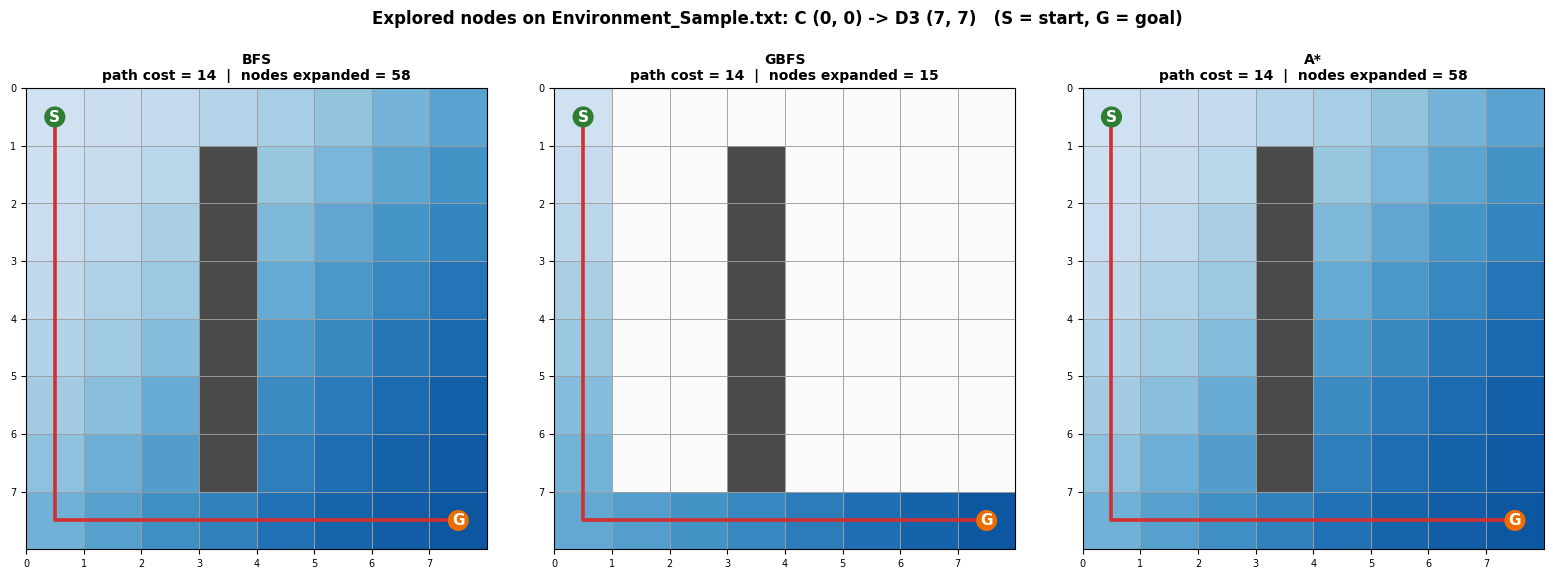

Nodes expanded for C -> D3:  BFS: 58  |  GBFS: 15  |  A*: 58
Path cost for C -> D3:       BFS: 14  |  GBFS: 14  |  A*: 14


In [65]:
def draw_search_panel(ax, grid, start, goal, algorithm):
    """Draws the explored region (shaded by expansion order) and the final path."""
    explored = []
    path, cost, expanded = search(grid, start, goal, algorithm, explored=explored)
    order = {cell: i for i, cell in enumerate(explored)}
    norm = Normalize(vmin=0, vmax=max(len(explored) - 1, 1))
    cmap = plt.get_cmap("Blues")
    rows, cols = grid["rows"], grid["cols"]
    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)
    ax.set_aspect("equal")

    for r in range(rows):
        for c in range(cols):
            cell = (r, c)
            if cell in grid["obstacles"]:
                color = "#4A4A4A"
            elif cell in order:
                color = cmap(0.2 + 0.65 * norm(order[cell]))
            else:
                color = "#FAFAFA"
            ax.add_patch(patches.Rectangle((c, r), 1, 1, facecolor=color, edgecolor="#9E9E9E", linewidth=0.6))

    if path:
        ax.plot([c + 0.5 for r, c in path], [r + 0.5 for r, c in path],
                color="#D32F2F", linewidth=2.6, zorder=4)
    ax.text(start[1] + 0.5, start[0] + 0.5, "S", ha="center", va="center",
            fontsize=11, fontweight="bold", color="white", zorder=6,
            bbox=dict(boxstyle="circle,pad=0.2", fc="#2E7D32", ec="none"))
    ax.text(goal[1] + 0.5, goal[0] + 0.5, "G", ha="center", va="center",
            fontsize=11, fontweight="bold", color="white", zorder=6,
            bbox=dict(boxstyle="circle,pad=0.2", fc="#EF6C00", ec="none"))
    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.tick_params(labelsize=7)
    ax.set_title(f"{algorithm}\npath cost = {cost}  |  nodes expanded = {expanded}", fontsize=10, fontweight="bold")
    return cost, expanded


def behaviour_figure(grid, start, goal, suptitle):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
    results = {}
    for ax, algo in zip(axes, ALGO_NAMES):
        results[algo] = draw_search_panel(ax, grid, start, goal, algo)
    fig.suptitle(suptitle, fontsize=12, fontweight="bold", y=0.99)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()
    return results



# ---- 8.1.1: every uploaded environment: charging station -> farthest dirty location ----
for run in iter_runs():
    run_header(run, "8.1.1 Behavioural visualisation")
    if not need_valid_env(run, "Behavioural visualisation"):
        continue
    grid = run["grid"]
    start_c = grid["charging_station"]
    farthest = max(grid["dirty_locations"], key=lambda d: search(grid, start_c, d, "BFS")[1])
    far_label = f"D{grid['dirty_locations'].index(farthest) + 1}"
    res = behaviour_figure(grid, start_c, farthest,
                           f"Explored nodes on {run['env_file']}: C {start_c} -> {far_label} {farthest}   (S = start, G = goal)")
    print(f"Nodes expanded for C -> {far_label}:  " + "  |  ".join(f"{a}: {res[a][1]}" for a in ALGO_NAMES))
    print(f"Path cost for C -> {far_label}:       " + "  |  ".join(f"{a}: {res[a][0]}" for a in ALGO_NAMES))

---

## **8.2 Performance Comparison**

Performance is measured with four metrics: **path cost** (battery use), **nodes expanded** (search effort), **runtime** (wall-clock time per query, averaged over repeated runs with `time.perf_counter`) and the **optimal-path rate** (share of queries where the returned cost equals the true shortest cost computed by BFS).

1. **8.2.1 Per-goal table & chart:** charging station $\to$ each dirty location, all three algorithms side by side.
2. **8.2.2 Aggregate table & chart:** all $C \to D_i$ and $D_i \to D_j$ pairs of each uploaded environment.
4. **8.2.3 Findings** are *generated from the measured numbers*, so the written conclusions always match the results above them.


################################################################################
# RUN 1/3: Environment.txt + Schedule.txt  |  8.2.1 / 8.2.2 Performance comparison
################################################################################
8.2.1  PER-GOAL COMPARISON  (Charging Station -> Di)  [Environment.txt]   [Time = mean microseconds per query]
--------------------------------------------------------------------------------------------------------
Goal            |            BFS            |            GBFS           |             A*            
                |   Cost   Nodes   Time(us) |   Cost   Nodes   Time(us) |   Cost   Nodes   Time(us) 
--------------------------------------------------------------------------------------------------------
D1 (5, 3)      |      9      40       78.7 |      9      10       29.3 |      9      25       97.5 
D2 (4, 4)      |      7      27       51.1 |      7       8       20.7 |      7      16       53.0 
D3 (1, 2)      |      6      23

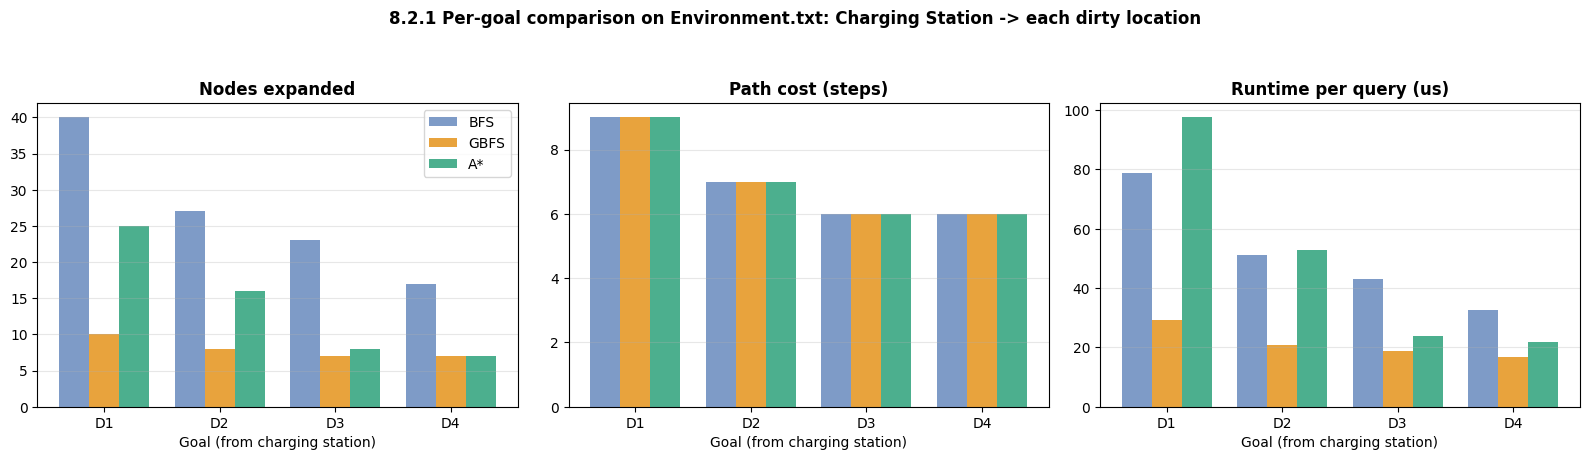


8.2.2  AGGREGATE COMPARISON over 16 location pairs (C->Di and Di->Dj)  [Environment.txt]
----------------------------------------------------------------------------------
Algorithm   Avg Path Cost   Avg Nodes Expanded    Avg Time (us)   Optimal Rate
----------------------------------------------------------------------------------
BFS         5.75            29.38                 74.8            100.0%
GBFS        5.75            7.06                  30.3            100.0%
A*          5.75            12.06                 38.6            100.0%
----------------------------------------------------------------------------------


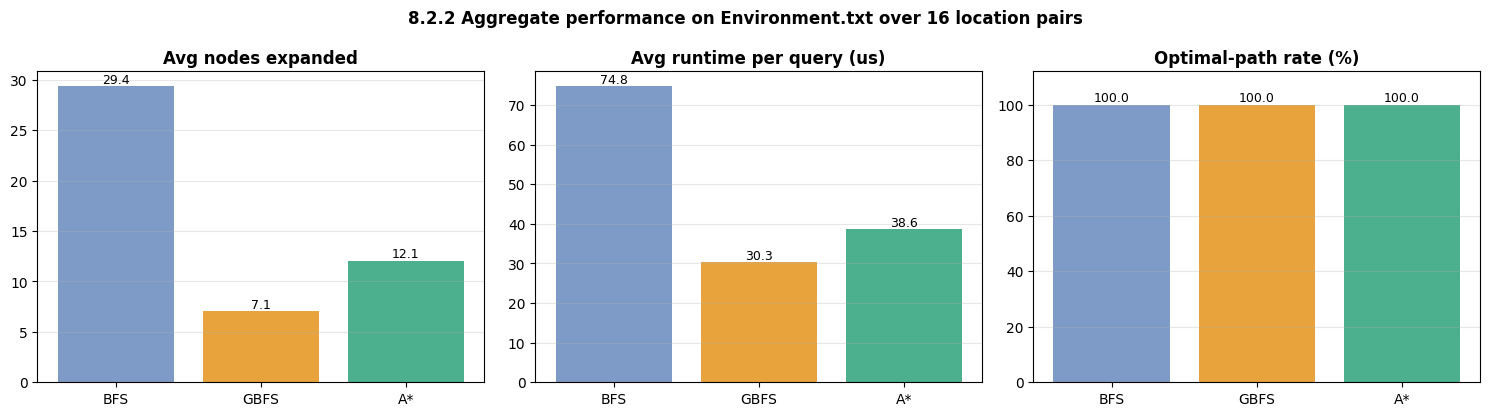


################################################################################
# RUN 2/3: Environment_Error.txt + Schedule_Error.txt  |  8.2.1 / 8.2.2 Performance comparison
################################################################################
[SKIPPED] Performance comparison needs a valid environment, but 'Environment_Error.txt' is not valid:
  - Dirty location (6, 7) is unreachable from charging station (0, 7).

################################################################################
# RUN 3/3: Environment_Sample.txt + Schedule_Sample.txt  |  8.2.1 / 8.2.2 Performance comparison
################################################################################
8.2.1  PER-GOAL COMPARISON  (Charging Station -> Di)  [Environment_Sample.txt]   [Time = mean microseconds per query]
--------------------------------------------------------------------------------------------------------
Goal            |            BFS            |            GBFS           |             

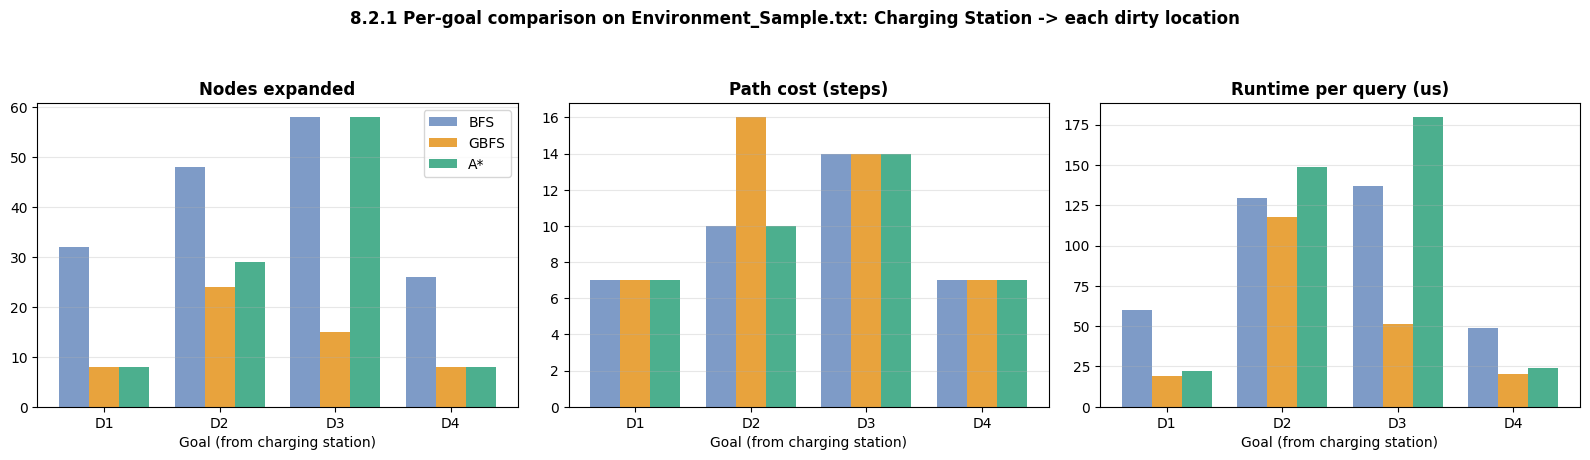


8.2.2  AGGREGATE COMPARISON over 16 location pairs (C->Di and Di->Dj)  [Environment_Sample.txt]
----------------------------------------------------------------------------------
Algorithm   Avg Path Cost   Avg Nodes Expanded    Avg Time (us)   Optimal Rate
----------------------------------------------------------------------------------
BFS         8.12            34.25                 67.3            100.0%
GBFS        8.88            10.75                 28.0            87.5%
A*          8.12            20.56                 79.7            100.0%
----------------------------------------------------------------------------------


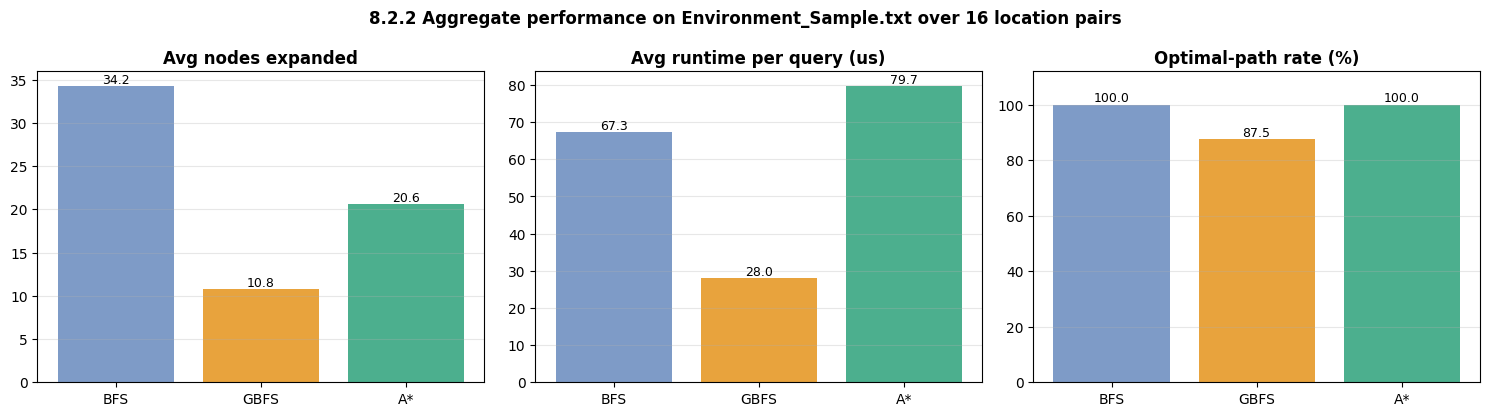

In [66]:
ALGO_COLORS = {"BFS": "#7E9BC7", "GBFS": "#E8A33D", "A*": "#4CAF8E"}


def time_search_us(grid, a, b, algo, reps=30):
    """Average runtime of one search query in microseconds (mean of `reps` repeated runs)."""
    t0 = time.perf_counter()
    for _ in range(reps):
        search(grid, a, b, algo)
    return (time.perf_counter() - t0) / reps * 1e6



def performance_for_run(run):
    """8.2.1 (per-goal) and 8.2.2 (aggregate) comparison for ONE environment. Stores AGG/pairs in `run`."""
    grid, name = run["grid"], run["env_file"]

    # ------------------------------------------------------------------
    # 8.2.1 Per-goal side-by-side table: Charging Station -> each Di
    # ------------------------------------------------------------------
    start_c = grid["charging_station"]
    n_goals = len(grid["dirty_locations"])
    per_goal = {}   # (goal_index, algo) -> (cost, nodes, microseconds)
    for i, goal in enumerate(grid["dirty_locations"], 1):
        for algo in ALGO_NAMES:
            _, cost, nodes = search(grid, start_c, goal, algo)
            per_goal[(i, algo)] = (cost, nodes, time_search_us(grid, start_c, goal, algo))

    print(f"8.2.1  PER-GOAL COMPARISON  (Charging Station -> Di)  [{name}]   [Time = mean microseconds per query]")
    line = "-" * 104
    print(line)
    print(f"{'Goal':<16}" + "".join(f"| {a:^26}" for a in ALGO_NAMES))
    print(f"{'':<16}" + "".join(f"| {'Cost':>6}{'Nodes':>8}{'Time(us)':>11} " for _ in ALGO_NAMES))
    print(line)
    for i, goal in enumerate(grid["dirty_locations"], 1):
        row = f"D{i} {str(goal):<12}"
        for algo in ALGO_NAMES:
            cost, nodes, us = per_goal[(i, algo)]
            row += f"| {cost:>6}{nodes:>8}{us:>11.1f} "
        print(row)
    print(line)

    # Chart: per-goal grouped bars (nodes, cost, time)
    labels = [f"D{i}" for i in range(1, n_goals + 1)]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    metrics = [("Nodes expanded", 1), ("Path cost (steps)", 0), ("Runtime per query (us)", 2)]
    width = 0.26
    for ax, (title, k) in zip(axes, metrics):
        for j, algo in enumerate(ALGO_NAMES):
            vals = [per_goal[(i, algo)][k] for i in range(1, n_goals + 1)]
            ax.bar([x + (j - 1) * width for x in range(n_goals)], vals, width, label=algo, color=ALGO_COLORS[algo])
        ax.set_xticks(range(n_goals))
        ax.set_xticklabels(labels)
        ax.set_title(title, fontweight="bold")
        ax.set_xlabel("Goal (from charging station)")
        ax.grid(axis="y", alpha=0.3)
    axes[0].legend()
    fig.suptitle(f"8.2.1 Per-goal comparison on {name}: Charging Station -> each dirty location",
                 fontsize=12, fontweight="bold", y=0.99)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

    # ------------------------------------------------------------------
    # 8.2.2 Aggregate over every C->Di and Di->Dj pair
    # ------------------------------------------------------------------
    pairs = [(start_c, d) for d in grid["dirty_locations"]]
    for d1 in grid["dirty_locations"]:
        for d2 in grid["dirty_locations"]:
            if d1 != d2:
                pairs.append((d1, d2))

    true_optimum = {pair: search(grid, pair[0], pair[1], "BFS")[1] for pair in pairs}   # BFS = ground truth
    AGG = {}
    for algo in ALGO_NAMES:
        costs, nodes_l, times_l, opt = [], [], [], 0
        for a, b in pairs:
            _, c, n = search(grid, a, b, algo)
            costs.append(c)
            nodes_l.append(n)
            times_l.append(time_search_us(grid, a, b, algo, reps=15))
            opt += (c == true_optimum[(a, b)])
        AGG[algo] = {"avg_cost": sum(costs) / len(costs), "avg_nodes": sum(nodes_l) / len(nodes_l),
                     "avg_us": sum(times_l) / len(times_l), "opt_rate": 100 * opt / len(pairs)}

    print(f"\n8.2.2  AGGREGATE COMPARISON over {len(pairs)} location pairs (C->Di and Di->Dj)  [{name}]")
    print("-" * 82)
    print(f"{'Algorithm':<12}{'Avg Path Cost':<16}{'Avg Nodes Expanded':<22}{'Avg Time (us)':<16}{'Optimal Rate'}")
    print("-" * 82)
    for algo in ALGO_NAMES:
        a = AGG[algo]
        print(f"{algo:<12}{a['avg_cost']:<16.2f}{a['avg_nodes']:<22.2f}{a['avg_us']:<16.1f}{a['opt_rate']:.1f}%")
    print("-" * 82)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, (title, key, fmt) in zip(axes, [("Avg nodes expanded", "avg_nodes", "{:.1f}"),
                                            ("Avg runtime per query (us)", "avg_us", "{:.1f}"),
                                            ("Optimal-path rate (%)", "opt_rate", "{:.1f}")]):
        vals = [AGG[a][key] for a in ALGO_NAMES]
        bars = ax.bar(ALGO_NAMES, vals, color=[ALGO_COLORS[a] for a in ALGO_NAMES])
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(v), ha="center", va="bottom", fontsize=9)
        ax.set_title(title, fontweight="bold")
        ax.grid(axis="y", alpha=0.3)
        if key == "opt_rate":
            ax.set_ylim(0, 112)
    fig.suptitle(f"8.2.2 Aggregate performance on {name} over {len(pairs)} location pairs", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

    run["AGG"], run["pairs"] = AGG, pairs


for run in iter_runs():
    run_header(run, "8.2.1 / 8.2.2 Performance comparison")
    if not need_valid_env(run, "Performance comparison"):
        continue
    performance_for_run(run)

In [67]:
# ------------------------------------------------------------------
# Resulting path + cost of BFS, GBFS and A*  (Charging Station -> each Di), per environment
# (new, separate cell: it only READS the existing functions; nothing else is modified)
# ------------------------------------------------------------------
def fmt_path(path):
    """(0,7)->(1,7)->... ; None -> 'no path'."""
    return "->".join(f"({r},{c})" for r, c in path) if path else "no path"


def paths_comparison_for_run(run):
    grid, name = run["grid"], run["env_file"]
    start_c = grid["charging_station"]
    print(f"RESULTING PATHS AND COSTS  (Charging Station -> Di)  [{name}]")
    print("=" * 100)
    for i, goal in enumerate(grid["dirty_locations"], 1):
        results = {algo: search(grid, start_c, goal, algo) for algo in ALGO_NAMES}   # (path, cost, nodes)
        print(f"Goal D{i} {goal}   (start {start_c})")
        print(f"  {'Algorithm':<10}{'Cost':<7}{'Nodes':<8}Path")
        print("  " + "-" * 96)
        for algo in ALGO_NAMES:
            path, cost, nodes = results[algo]
            print(f"  {algo:<10}{cost:<7}{nodes:<8}{fmt_path(path)}")
        distinct = {tuple(p) if p else None for p, _, _ in results.values()}
        if len(distinct) == 1:
            print("  -> All three algorithms returned the SAME path.")
        else:
            best = min(c for _, c, _ in results.values())
            worse = [a for a in ALGO_NAMES if results[a][1] > best]
            print(f"  -> Paths DIFFER. Optimal cost = {best}; sub-optimal: {', '.join(worse) if worse else 'none (equal-cost alternatives)'}.")
        print()


for run in iter_runs():
    run_header(run, "Resulting paths and costs")
    if not need_valid_env(run, "Resulting paths and costs"):
        continue
    paths_comparison_for_run(run)


################################################################################
# RUN 1/3: Environment.txt + Schedule.txt  |  Resulting paths and costs
################################################################################
RESULTING PATHS AND COSTS  (Charging Station -> Di)  [Environment.txt]
Goal D1 (5, 3)   (start (0, 7))
  Algorithm Cost   Nodes   Path
  ------------------------------------------------------------------------------------------------
  BFS       9      40      (0,7)->(1,7)->(2,7)->(3,7)->(4,7)->(5,7)->(5,6)->(5,5)->(5,4)->(5,3)
  GBFS      9      10      (0,7)->(1,7)->(2,7)->(3,7)->(4,7)->(5,7)->(5,6)->(5,5)->(5,4)->(5,3)
  A*        9      25      (0,7)->(1,7)->(2,7)->(3,7)->(4,7)->(5,7)->(5,6)->(5,5)->(5,4)->(5,3)
  -> All three algorithms returned the SAME path.

Goal D2 (4, 4)   (start (0, 7))
  Algorithm Cost   Nodes   Path
  ------------------------------------------------------------------------------------------------
  BFS       7      27      (0

In [68]:
# ------------------------------------------------------------------
# 8.2.3 Findings generated directly from the measurements (one block per run)
# (every number comes from the uploaded Environment/Schedule files)
# ------------------------------------------------------------------
def print_findings(run):
    AGG, pairs = run["AGG"], run["pairs"]
    name = run["env_file"]
    red = (1 - AGG["A*"]["avg_nodes"] / AGG["BFS"]["avg_nodes"]) * 100
    fewest = min(ALGO_NAMES, key=lambda a: AGG[a]["avg_nodes"])
    fastest = min(ALGO_NAMES, key=lambda a: AGG[a]["avg_us"])
    print("=" * 82)
    print(f"8.2.3  FINDINGS for {name} (generated from the numbers above)")
    print("=" * 82)
    print(f" 1. Optimality on {name}: BFS {AGG['BFS']['opt_rate']:.1f}%, A* {AGG['A*']['opt_rate']:.1f}%, "
          f"GBFS {AGG['GBFS']['opt_rate']:.1f}% of the {len(pairs)} location pairs returned the shortest path.")
    print(f" 2. Search effort: A* expanded {AGG['A*']['avg_nodes']:.2f} nodes on average vs BFS {AGG['BFS']['avg_nodes']:.2f} "
          f"-> {red:.1f}% fewer, with identical path cost. GBFS expanded {AGG['GBFS']['avg_nodes']:.2f}. "
          f"Fewest expansions: {fewest}.")
    print(f" 3. Runtime: average per query BFS {AGG['BFS']['avg_us']:.1f} us, GBFS {AGG['GBFS']['avg_us']:.1f} us, "
          f"A* {AGG['A*']['avg_us']:.1f} us. Fastest: {fastest}.")
    gb = AGG["GBFS"]["opt_rate"]
    gb_txt = (f"it happened to be optimal on all {len(pairs)} pairs of this map"
              if gb == 100 else f"it was optimal on only {gb:.1f}% of the pairs of this map")
    print(f" 4. GBFS optimality is not guaranteed (it ranks nodes by h(n) only): {gb_txt}.")
    print(f" 5. Recommendation: A* - optimal like BFS, with {red:.0f}% fewer expansions on this map.")


for run in iter_runs():
    run_header(run, "8.2.3 Findings")
    if not need_valid_env(run, "Findings"):
        continue
    print_findings(run)


################################################################################
# RUN 1/3: Environment.txt + Schedule.txt  |  8.2.3 Findings
################################################################################
8.2.3  FINDINGS for Environment.txt (generated from the numbers above)
 1. Optimality on Environment.txt: BFS 100.0%, A* 100.0%, GBFS 100.0% of the 16 location pairs returned the shortest path.
 2. Search effort: A* expanded 12.06 nodes on average vs BFS 29.38 -> 58.9% fewer, with identical path cost. GBFS expanded 7.06. Fewest expansions: GBFS.
 3. Runtime: average per query BFS 74.8 us, GBFS 30.3 us, A* 38.6 us. Fastest: GBFS.
 4. GBFS optimality is not guaranteed (it ranks nodes by h(n) only): it happened to be optimal on all 16 pairs of this map.
 5. Recommendation: A* - optimal like BFS, with 59% fewer expansions on this map.

################################################################################
# RUN 2/3: Environment_Error.txt + Schedule_Error.txt  

## **9. Constraint Satisfaction Problem (CSP): Cleaning Task Scheduling**

### **CSP Formulation**
- **Variables:** V = {D₁, D₂, …, Dₙ}, where each Dᵢ represents a dirty location (one cleaning task) defined in the loaded environment file.
- **Domains:** For each variable Dᵢ, Dom(Dᵢ) = {T₁, T₂, …, Tₘ}, where each Tⱼ represents an available cleaning time slot.
- **Constraints:**
  1. **Slot-Exclusivity:** No two cleaning tasks may be assigned the same time slot:
     ```
     for all i ≠ j:   slot(Dᵢ) ≠ slot(Dⱼ)
     ```
  2. **Precedence Constraints:** Task Dₐ must be cleaned before task D_b:
     ```
     slot(Dₐ) < slot(D_b)
     ```
  3. **Latest-Slot Constraints:** Task D_c must be completed no later than time slot T_k:
     ```
     slot(D_c) ≤ slot(T_k)
     ```

  Here `slot(Dᵢ)` denotes the time slot number assigned to task Dᵢ (e.g. `slot(T3) = 3`).

---

### **CSP Solver Implementation Details**
1. **Variable Selection (`select_unassigned_variable`):**
   - **Minimum Remaining Values (MRV):** Selects the variable with the fewest remaining candidate values in its domain.
   - **Degree Heuristic (Tie-breaker):** If multiple variables tie under MRV, selects the variable involved in the largest number of constraints with other unassigned variables.
2. **Value Ordering (`order_domain_values`):**
   - **Least Constraining Value (LCV):** Orders candidate time slots by the number of choices they eliminate from the domains of remaining unassigned variables (ascending order of elimination).
3. **Constraint Consistency Check (`is_consistent`):**
   - Evaluates slot-exclusivity, precedence, and latest-slot constraints for any proposed assignment.
4. **Forward Checking (`forward_check`):**
   - Filters inconsistent time slots from neighbor domains (slot-exclusivity and precedence). If any domain becomes empty, detects failure early and initiates backtracking.
5. **Node Consistency (`enforce_node_consistency`):**
   - Latest-slot constraints are *unary* (they involve a single task), so they are enforced **once, up front**, by pruning each task's domain (e.g. `D4 <= T3` removes `T4, T5, ...` from `Dom(D4)`) before search starts. Because of this, `forward_check` does not need to prune latest-slot values again: it deals only with the *binary* constraints between a newly assigned task and its unassigned neighbours.
   - `is_consistent` still re-checks the latest-slot bound on every proposed assignment as a safety net, so the solver stays correct even when it is called with un-pruned domains.
6. **Guarded solving (`solve_csp`):** the solver is only run when `validate_schedule` passes. If validation fails (unknown label, missing slot, wrong counts, ...) the solver is **blocked** and the exact validation errors are reported.

In [69]:
def slot_num(slot):
    """Extracts the integer index from a time slot label (e.g. 'T3' -> 3)."""
    return int(slot[1:])


def is_consistent(variable, value, assignment, constraints):
    """Checks precedence, latest-slot, and slot-exclusivity constraints.
    Returns True if the proposed assignment violates no constraints, False otherwise."""
    val_idx = slot_num(value)

    # 1. Slot-exclusivity constraint (at most one task per slot)
    for other_var, assigned_val in assignment.items():
        if other_var != variable and assigned_val == value:
            return False

    # 2. Latest-slot constraint (task must be cleaned <= latest_slot)
    #    (also enforced up-front by enforce_node_consistency; re-checked here as a safety net)
    for task, latest_slot in constraints.get("latest_slot", []):
        if variable == task:
            if val_idx > slot_num(latest_slot):
                return False

    # 3. Precedence constraint (before_task < after_task)
    for before_task, after_task in constraints.get("precedence", []):
        if variable == before_task and after_task in assignment:
            if val_idx >= slot_num(assignment[after_task]):
                return False
        if variable == after_task and before_task in assignment:
            if slot_num(assignment[before_task]) >= val_idx:
                return False

    return True


def get_degree(var, assignment, constraints):
    """Counts active constraints connecting var to other unassigned variables."""
    degree = 0
    for before, after in constraints.get("precedence", []):
        if var == before and after not in assignment:
            degree += 1
        elif var == after and before not in assignment:
            degree += 1
    return degree


def select_unassigned_variable(assignment, domains, constraints):
    """Selects unassigned variable via MRV, tie-broken by Degree heuristic."""
    unassigned = [v for v in domains if v not in assignment]
    min_remaining = min(len(domains[v]) for v in unassigned)
    mrv_candidates = [v for v in unassigned if len(domains[v]) == min_remaining]

    if len(mrv_candidates) == 1:
        return mrv_candidates[0]

    return max(mrv_candidates, key=lambda var: get_degree(var, assignment, constraints))


def order_domain_values(variable, assignment, domains, constraints):
    """Orders domain values using the Least Constraining Value (LCV) heuristic."""
    def count_eliminated(value):
        eliminated = 0
        val_idx = slot_num(value)
        for other in domains:
            if other != variable and other not in assignment:
                for other_val in domains[other]:
                    other_idx = slot_num(other_val)
                    if other_val == value:
                        eliminated += 1
                    for before, after in constraints.get("precedence", []):
                        if variable == before and other == after and val_idx >= other_idx:
                            eliminated += 1
                        elif variable == after and other == before and other_idx >= val_idx:
                            eliminated += 1
        return eliminated

    return sorted(domains[variable], key=count_eliminated)


def enforce_node_consistency(domains, constraints):
    """Prunes each domain with the UNARY latest-slot constraints (done once, before search)."""
    pruned = {var: list(vals) for var, vals in domains.items()}
    for task, latest_slot in constraints.get("latest_slot", []):
        if task in pruned:
            limit = slot_num(latest_slot)
            pruned[task] = [s for s in pruned[task] if slot_num(s) <= limit]
    return pruned


def forward_check(variable, value, assignment, domains, constraints):
    """Removes values from unassigned variables that violate the BINARY constraints
    (slot-exclusivity, precedence) with (variable, value).
    Latest-slot (unary) bounds are already applied by enforce_node_consistency.
    Returns updated domains, or None if any unassigned domain is wiped out."""
    new_domains = {var: list(vals) for var, vals in domains.items()}
    val_idx = slot_num(value)

    for other in new_domains:
        if other != variable and other not in assignment:
            filtered = []
            for other_val in new_domains[other]:
                other_idx = slot_num(other_val)
                if other_val == value:
                    continue  # Violates slot-exclusivity

                violates = False
                for before, after in constraints.get("precedence", []):
                    if variable == before and other == after and val_idx >= other_idx:
                        violates = True
                        break
                    if variable == after and other == before and other_idx >= val_idx:
                        violates = True
                        break

                if not violates:
                    filtered.append(other_val)

            if not filtered:
                return None  # Domain wipe-out: trigger backtracking
            new_domains[other] = filtered

    return new_domains


def backtracking_search(variables, domains, constraints):
    """Backtracking CSP solver with Node Consistency, MRV, Degree, LCV and Forward Checking.
    Returns complete assignment dict if feasible, or None if no solution exists."""
    start_domains = enforce_node_consistency(domains, constraints)
    if any(len(vals) == 0 for vals in start_domains.values()):
        return None                                   # a latest-slot bound already empties a domain

    def backtrack(assignment, current_domains):
        if len(assignment) == len(variables):
            return assignment

        var = select_unassigned_variable(assignment, current_domains, constraints)
        for value in order_domain_values(var, assignment, current_domains, constraints):
            if is_consistent(var, value, assignment, constraints):
                assignment[var] = value
                updated_domains = forward_check(var, value, assignment, current_domains, constraints)
                if updated_domains is not None:
                    result = backtrack(assignment, updated_domains)
                    if result is not None:
                        return result
                del assignment[var]

        return None

    return backtrack({}, start_domains)

## **10. Schedule File Loading & Robust Validation**

1. **Slot availability:** Number of time slots must be $\ge$ number of dirty locations.
2. **Label correspondence:** Task labels in constraints must exist in Environment File Loading & Validation.
3. **Minimum constraints:** At least **3 precedence** and **2 latest-slot** constraints must be defined.
4. **Informative errors:** Validation must clearly state the exact cause of any error.

**Robustness additions (applied to every schedule file loaded)**
- Task labels and slot names written in the schedule file are parsed **case-insensitively** (`d1`, `t3` are normalised to `D1`, `T3`).- The declared counts (slots / precedence / latest-slot) must match the number of constraint pairs actually present in the schedule file.
- **If validation fails the solver does not run** (`solve_csp` returns `INVALID_INPUT`): a constraint in the schedule file such as `(D2,D9)`, where `D9` is not a dirty location of the loaded environment, can therefore never be silently ignored.

In [70]:
def build_csp(grid, sched_text):
    """Builds the CSP (variables, dirty_map, domains, constraints) from schedule text.
    Parsing is case-insensitive: 'd1' / 't3' are normalised to 'D1' / 'T3'."""
    variables = [f"D{i + 1}" for i in range(len(grid["dirty_locations"]))]
    dirty_map = {f"D{i + 1}": coord for i, coord in enumerate(grid["dirty_locations"])}

    # Declared counts = integers that are NOT inside a '(...)' constraint pair
    outside_pairs = re.sub(r"\([^)]*\)", " ", sched_text)
    counts = [int(x) for x in re.findall(r"(?<![A-Za-z0-9_])\d+(?![A-Za-z0-9_])", outside_pairs)]
    parse_errors = []
    if len(counts) < 3:
        parse_errors.append(f"Schedule file must declare 3 counts (time slots, precedence constraints, "
                            f"latest-slot constraints) but only {len(counts)} were found.")
    num_slots = counts[0] if len(counts) > 0 else 0
    num_prec = counts[1] if len(counts) > 1 else 0
    num_latest = counts[2] if len(counts) > 2 else 0

    pairs = [(a.upper(), b.upper()) for a, b in
             re.findall(r"\(\s*([A-Za-z0-9_]+)\s*,\s*([A-Za-z0-9_]+)\s*\)", sched_text)]
    if len(pairs) != num_prec + num_latest:
        parse_errors.append(f"Declared {num_prec} precedence + {num_latest} latest-slot constraints "
                            f"but the file contains {len(pairs)} constraint pairs.")

    time_slots = [f"T{i + 1}" for i in range(num_slots)]
    domains = {var: list(time_slots) for var in variables}
    constraints = {
        "time_slots": time_slots,
        "precedence": pairs[:num_prec],
        "latest_slot": pairs[num_prec:num_prec + num_latest],
        "declared_slots": num_slots,
        "declared_prec": num_prec,
        "declared_latest": num_latest,
        "parse_errors": parse_errors,
    }
    return variables, dirty_map, domains, constraints


def load_csp(grid, sched_filename):
    """Loads the scheduling problem from file and creates variables matching Environment dirty locations."""
    if not os.path.exists(sched_filename):
        raise FileNotFoundError(f"'{sched_filename}' not found. Run the upload cell in Section 1 "
                                f"or place the file in {os.getcwd()}.")
    with open(sched_filename, "r") as f:
        return build_csp(grid, f.read())


def validate_schedule(variables, constraints, verbose=True):
    """Validates the CSP constraints against Handout Section 6.4 requirements.
    Returns (is_valid, list_of_errors)."""
    errors = list(constraints.get("parse_errors", []))
    num_slots = len(constraints["time_slots"])
    num_vars = len(variables)

    # 1. Number of available slots >= dirty locations
    if num_slots < num_vars:
        errors.append(
            f"Insufficient time slots: {num_slots} slots available for {num_vars} tasks. "
            f"Slot exclusivity requires at least {num_vars} slots."
        )

    # 2. Minimum constraint counts per Handout 6.4
    if len(constraints["precedence"]) < 3:
        errors.append(f"Handout requirement: At least 3 precedence constraints required (found {len(constraints['precedence'])}).")
    if len(constraints["latest_slot"]) < 2:
        errors.append(f"Handout requirement: At least 2 latest-slot constraints required (found {len(constraints['latest_slot'])}).")

    # 3. Label correspondence with Environment
    for before, after in constraints["precedence"]:
        for label in (before, after):
            if label not in variables:
                errors.append(f"Precedence constraint ({before},{after}) references unknown task label '{label}'. Valid tasks: {variables}.")
        if before == after:
            errors.append(f"Precedence constraint ({before},{after}) makes a task precede itself.")

    for task, latest in constraints["latest_slot"]:
        if task not in variables:
            errors.append(f"Latest-slot constraint ({task},{latest}) references unknown task label '{task}'. Valid tasks: {variables}.")
        if latest not in constraints["time_slots"]:
            errors.append(f"Latest-slot constraint ({task},{latest}) references unknown time slot '{latest}'. Available slots: {constraints['time_slots']}.")

    is_valid = len(errors) == 0
    if verbose:
        if not is_valid:
            print("[WARNING] Schedule validation detected issues:")
            for err in errors:
                print(f"  - {err}")
        else:
            print("[SUCCESS] Schedule format and label checks passed (feasibility is checked by the CSP solver in the next step).")
    return is_valid, errors


def print_schedule_config(variables, constraints, source=""):
    """Prints the scheduling configuration (needed for the test-run screenshots)."""
    print(f"Schedule configuration{(' (' + source + ')') if source else ''}:")
    print(f"  CSP Variables (from environment): {variables}")
    print(f"  Available Time Slots ({len(constraints['time_slots'])}): {constraints['time_slots']}")
    print(f"  Precedence Constraints ({len(constraints['precedence'])}): {constraints['precedence']}")
    print(f"  Latest-Slot Constraints ({len(constraints['latest_slot'])}): {constraints['latest_slot']}")



def load_and_check_schedule(run):
    """Loads, prints and validates one run's schedule file (results stored in `run`)."""
    run_header(run, "Schedule")
    if run["grid"] is None:
        print(f"[SKIPPED] Environment '{run['env_file']}' could not be loaded, so no CSP can be built.")
        return
    try:
        variables, dirty_map, domains, constraints = load_csp(run["grid"], run["sched_file"])
    except Exception as exc:
        run["sched_ok"], run["csp_ready"] = False, False
        run["sched_errors"] = [f"{type(exc).__name__}: {exc}"]
        print(f"[ERROR] Could not load {run['sched_file']}: {run['sched_errors'][0]}")
        return
    run.update(variables=variables, dmap=dirty_map, domains=domains, cons=constraints, csp_ready=True)
    print_schedule_config(variables, constraints, run["sched_file"])
    run["sched_ok"], run["sched_errors"] = validate_schedule(variables, constraints)


for run in iter_runs():
    load_and_check_schedule(run)


################################################################################
# RUN 1/3: Environment.txt + Schedule.txt  |  Schedule
################################################################################
Schedule configuration (Schedule.txt):
  CSP Variables (from environment): ['D1', 'D2', 'D3', 'D4']
  Available Time Slots (4): ['T1', 'T2', 'T3', 'T4']
  Precedence Constraints (3): [('D3', 'D1'), ('D1', 'D2'), ('D3', 'D4')]
  Latest-Slot Constraints (2): [('D1', 'T2'), ('D4', 'T3')]
[SUCCESS] Schedule format and label checks passed (feasibility is checked by the CSP solver in the next step).

################################################################################
# RUN 2/3: Environment_Error.txt + Schedule_Error.txt  |  Schedule
################################################################################
Schedule configuration (Schedule_Error.txt):
  CSP Variables (from environment): ['D1', 'D2', 'D3', 'D4']
  Available Time Slots (4): ['T1', 'T2', 'T3', 'T

## **11. Solving the Schedule & Programmatic Constraint Verification**

Rather than printing hardcoded success notices, `verify_csp_schedule` performs actual programmatic assertions across all slot-exclusivity, precedence, and latest-slot constraints.

In [71]:
def diagnose_infeasibility(variables, constraints):
    """Explains WHY a (valid) schedule problem has no solution, using structural checks:
    too few slots, cyclic precedence, empty time windows, over-subscribed deadlines."""
    reasons = []
    slots = constraints["time_slots"]
    n = len(slots)
    if n < len(variables):
        reasons.append(f"only {n} time slots for {len(variables)} tasks (slot-exclusivity needs >= {len(variables)})")

    succ = {v: [] for v in variables}
    indeg = {v: 0 for v in variables}
    for a, b in constraints["precedence"]:
        if a in succ and b in succ:
            succ[a].append(b)
            indeg[b] += 1

    # Kahn's algorithm: tasks that can never be placed in a topological order lie on / behind a cycle
    queue = [v for v in variables if indeg[v] == 0]
    topo, deg = [], dict(indeg)
    while queue:
        v = queue.pop(0)
        topo.append(v)
        for w in succ[v]:
            deg[w] -= 1
            if deg[w] == 0:
                queue.append(w)
    stuck = [v for v in variables if v not in topo]
    if stuck:
        reasons.append(f"cyclic precedence constraints among {stuck} (each of them must be cleaned before another one in the cycle)")
        return reasons

    earliest = {v: 1 for v in variables}
    for v in topo:
        for w in succ[v]:
            earliest[w] = max(earliest[w], earliest[v] + 1)
    latest = {v: n for v in variables}
    for task, lim in constraints["latest_slot"]:
        if task in latest:
            latest[task] = min(latest[task], slot_num(lim))
    for v in reversed(topo):
        for w in succ[v]:
            latest[v] = min(latest[v], latest[w] - 1)
    for v in variables:
        if earliest[v] > latest[v]:
            limit = f"T{latest[v]}" if latest[v] >= 1 else "before T1"
            reasons.append(f"{v} needs slot >= T{earliest[v]} (because of its predecessors) "
                           f"but must be finished by {limit} (its own latest-slot bound / its successors' deadlines)")
    for k in range(1, n + 1):
        due = [v for v in variables if latest[v] <= k]
        if len(due) > k:
            reasons.append(f"{len(due)} tasks {due} must all finish by T{k}, but only {k} slots exist up to T{k}")
            break
    return reasons


def solve_csp(variables, domains, constraints, validate=True, verbose=True):
    """Guarded CSP solving. Returns (solution_or_None, status) with status one of:
       'SOLVED'        - feasible schedule found
       'INFEASIBLE'    - input valid, but no schedule satisfies all constraints
       'INVALID_INPUT' - validation failed, solver NOT run"""
    if validate:
        ok, errors = validate_schedule(variables, constraints, verbose=False)
        if not ok:
            if verbose:
                print("[BLOCKED] Schedule validation failed - the CSP solver was NOT run:")
                for err in errors:
                    print(f"  - {err}")
            return None, "INVALID_INPUT"
    solution = backtracking_search(variables, domains, constraints)
    return solution, ("SOLVED" if solution is not None else "INFEASIBLE")


def order_from_solution(solution):
    """Cleaning order (task labels) sorted by assigned time slot."""
    return [task for task, slot in sorted(solution.items(), key=lambda x: slot_num(x[1]))]


def verify_csp_schedule(solution, constraints, variables):
    """Demonstrates that the generated schedule programmatically satisfies all specified constraints."""
    if solution is None:
        print("[FAIL] Cannot verify: No schedule provided (solution is None).")
        return False

    print("=" * 70)
    print("PROGRAMMATIC CSP CONSTRAINT SATISFACTION VERIFICATION")
    print("=" * 70)
    all_passed = True

    # 1. Variable Completeness
    missing = [v for v in variables if v not in solution]
    if missing:
        print(f"[FAIL] Missing assignments for variables: {missing}")
        all_passed = False
    else:
        print(f"[PASS] Variable Completeness: All {len(variables)} tasks {variables} are assigned.")

    # 2. Slot-Exclusivity Demonstration
    assigned_slots = list(solution.values())
    unique_slots = set(assigned_slots)
    if len(assigned_slots) == len(unique_slots):
        print(f"[PASS] Slot-Exclusivity: All {len(assigned_slots)} tasks assigned to distinct time slots.")
        for task in sorted(solution.keys(), key=lambda t: slot_num(solution[t])):
            print(f"       -> {task} exclusively assigned to {solution[task]}")
    else:
        print(f"[FAIL] Slot-Exclusivity violated: Multiple tasks assigned to same slot! ({assigned_slots})")
        all_passed = False

    # 3. Precedence Constraints Demonstration
    print("\nPrecedence Constraints Verification:")
    for before, after in constraints.get("precedence", []):
        t_before = slot_num(solution[before])
        t_after = slot_num(solution[after])
        passed = t_before < t_after
        status = "SATISFIED" if passed else "VIOLATED"
        print(f"  [{status}] {before} ({solution[before]}, slot {t_before}) must precede {after} ({solution[after]}, slot {t_after}) -> {t_before} < {t_after}")
        if not passed:
            all_passed = False

    # 4. Latest-Slot Constraints Demonstration
    print("\nLatest-Slot Constraints Verification:")
    for task, latest in constraints.get("latest_slot", []):
        t_task = slot_num(solution[task])
        t_limit = slot_num(latest)
        passed = t_task <= t_limit
        status = "SATISFIED" if passed else "VIOLATED"
        print(f"  [{status}] {task} ({solution[task]}, slot {t_task}) must be cleaned by {latest} (slot {t_limit}) -> {t_task} <= {t_limit}")
        if not passed:
            all_passed = False

    print("-" * 70)
    overall_status = "ALL CONSTRAINTS FULLY SATISFIED (PASSED)" if all_passed else "SOME CONSTRAINTS VIOLATED (FAILED)"
    print(f"Overall CSP Verification: {overall_status}")
    print("=" * 70 + "\n")
    return all_passed


def print_schedule_table(solution, dirty_map):
    ordered_schedule = sorted(solution.items(), key=lambda x: slot_num(x[1]))
    print(f"{'Time Slot':<12} | {'Cleaning Task':<16} | {'Grid Coordinate'}")
    print("-" * 50)
    for task, slot in ordered_schedule:
        print(f"{slot:<12} | {task:<16} | {dirty_map[task]}")
    print()



def solve_and_report(run):
    """Runs the guarded CSP solver for one run and prints the schedule + verification."""
    run_header(run, "CSP solving")
    if not run.get("csp_ready"):
        print("[SKIPPED] The CSP could not be built (environment or schedule file could not be loaded).")
        run.update(solution=None, csp_status="NOT_RUN", order=None)
        return
    solution, csp_status = solve_csp(run["variables"], run["domains"], run["cons"], validate=True)
    run.update(solution=solution, csp_status=csp_status,
               order=order_from_solution(solution) if solution is not None else None)
    print("=" * 55)
    print(f"CSP CLEANING SCHEDULE RESULTS  [{run['sched_file']}]")
    print("=" * 55)
    print(f"Status: {csp_status}\n")
    if solution is not None:
        print_schedule_table(solution, run["dmap"])
        verify_csp_schedule(solution, run["cons"], run["variables"])
    elif csp_status == "INFEASIBLE":
        print("Reason(s):", "; ".join(diagnose_infeasibility(run["variables"], run["cons"])) or "constraints are jointly infeasible")


for run in iter_runs():
    solve_and_report(run)


################################################################################
# RUN 1/3: Environment.txt + Schedule.txt  |  CSP solving
################################################################################
CSP CLEANING SCHEDULE RESULTS  [Schedule.txt]
Status: SOLVED

Time Slot    | Cleaning Task    | Grid Coordinate
--------------------------------------------------
T1           | D3               | (1, 2)
T2           | D1               | (5, 3)
T3           | D4               | (6, 7)
T4           | D2               | (4, 4)

PROGRAMMATIC CSP CONSTRAINT SATISFACTION VERIFICATION
[PASS] Variable Completeness: All 4 tasks ['D1', 'D2', 'D3', 'D4'] are assigned.
[PASS] Slot-Exclusivity: All 4 tasks assigned to distinct time slots.
       -> D3 exclusively assigned to T1
       -> D1 exclusively assigned to T2
       -> D4 exclusively assigned to T3
       -> D2 exclusively assigned to T4

Precedence Constraints Verification:
  [SATISFIED] D3 (T1, slot 1) must precede D1 (T

# **12. Schedule Visualization**
Visualizes the planned visiting order on the grid for every uploaded pair. Infeasible schedules are not drawn; they are reported by the CSP solver in Section 11.


################################################################################
# RUN 1/3: Environment.txt + Schedule.txt  |  Schedule visualization
################################################################################


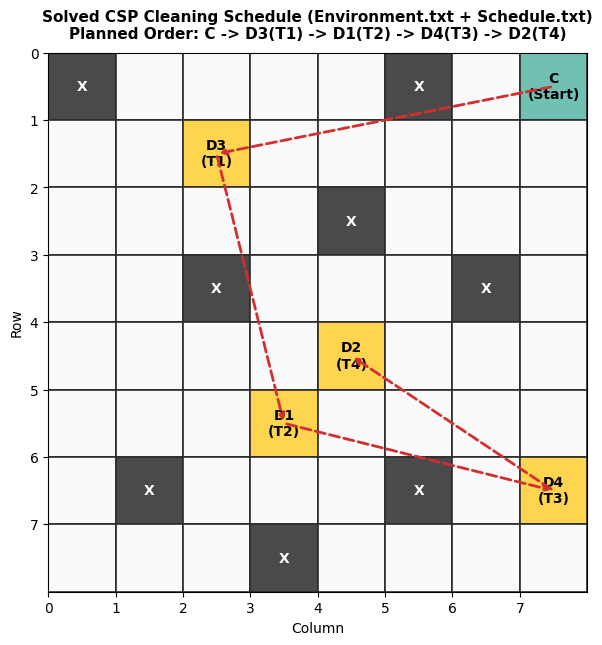


################################################################################
# RUN 2/3: Environment_Error.txt + Schedule_Error.txt  |  Schedule visualization
################################################################################
Cannot visualize: no feasible schedule (CSP status = INFEASIBLE).

################################################################################
# RUN 3/3: Environment_Sample.txt + Schedule_Sample.txt  |  Schedule visualization
################################################################################


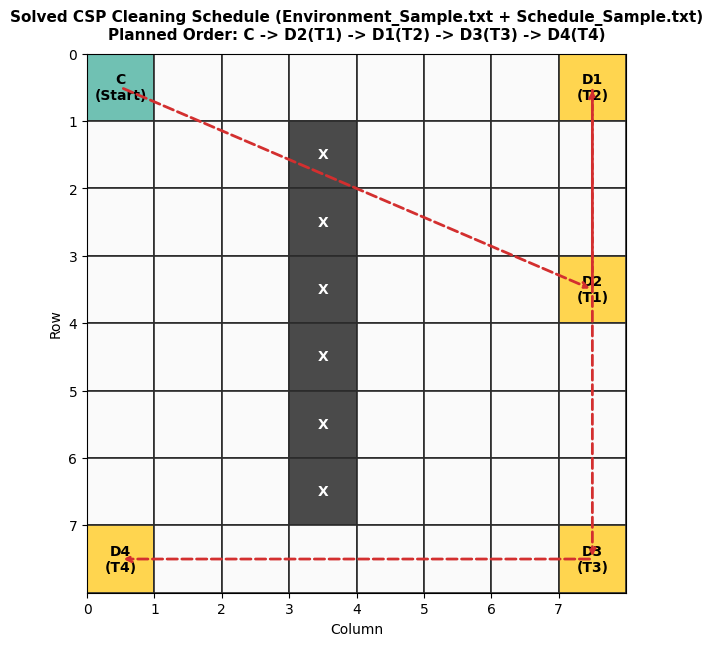

In [72]:
def visualize_csp_schedule(grid, solution, source=""):
    """Visualizes the planned cleaning sequence generated by CSP."""
    if solution is None:
        print("Cannot visualize: No feasible schedule found.")
        return
    if grid["charging_station"] is None:
        print("Cannot visualize: the environment has no charging station.")
        return

    rows, cols = grid["rows"], grid["cols"]
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)
    ax.set_aspect("equal")

    dirty_map = {f"D{i+1}": c for i, c in enumerate(grid["dirty_locations"])}

    for r in range(rows):
        for c in range(cols):
            color, label, tc = "#FAFAFA", "", "black"
            if (r, c) in grid["obstacles"]:
                color, label, tc = "#4A4A4A", "X", "white"
            elif (r, c) in grid["dirty_locations"]:
                color = "#FFD54F"
                idx = grid["dirty_locations"].index((r, c)) + 1
                task = f"D{idx}"
                slot = solution.get(task, "?")
                label = f"{task}\n({slot})"
            elif (r, c) == grid["charging_station"]:
                color, label, tc = "#70C1B3", "C\n(Start)", "black"

            rect = patches.Rectangle((c, r), 1, 1, facecolor=color, edgecolor="#2B2B2B", linewidth=1.2)
            ax.add_patch(rect)
            if label:
                ax.text(c + 0.5, r + 0.5, label, ha="center", va="center", fontsize=10, fontweight="bold", color=tc)

    ordered_tasks = sorted(solution.items(), key=lambda x: slot_num(x[1]))
    waypoints = [grid["charging_station"]] + [dirty_map[task] for task, _ in ordered_tasks]

    for i in range(len(waypoints) - 1):
        r1, c1 = waypoints[i]
        r2, c2 = waypoints[i + 1]
        ax.annotate(
            "", xy=(c2 + 0.5, r2 + 0.5), xytext=(c1 + 0.5, r1 + 0.5),
            arrowprops=dict(arrowstyle="->", color="#D32F2F", lw=2, ls="--")
        )

    order_str = " -> ".join(["C"] + [f"{t}({s})" for t, s in ordered_tasks])
    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_title(f"Solved CSP Cleaning Schedule{(' (' + source + ')') if source else ''}\nPlanned Order: {order_str}", fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    plt.grid(False)
    plt.show()


for run in iter_runs():
    run_header(run, "Schedule visualization")
    if run["solution"] is None:
        print(f"Cannot visualize: no feasible schedule (CSP status = {run['csp_status']}).")
        continue
    visualize_csp_schedule(run["grid"], run["solution"], source=run["label"])

## **13. System Integration:** `execute_schedule`

Required integration function:
`execute_schedule(grid, charging_station, schedule, algorithm)` -> `(complete_path, total_cost, success)`

### **Required Procedure**
1. Initialize the robot's current position to the charging station.
2. Obtain the cleaning locations in the order specified by the CSP-generated schedule.
3. For each cleaning location, call `search` using the robot's current position as the start state and the next cleaning location as the goal state.
4. Append each returned path to `complete_path`, avoiding duplication of shared endpoints.
5. Update the robot's current position and mark the reached location as cleaned.
6. After all cleaning locations have been visited, call `search` again to find a path back to the charging station.
7. Combine the paths and calculate the total navigation cost.
8. Report the complete journey, total cost, and execution status.
9. If a required path cannot be found, the program must report failure rather than claim that the cleaning task was completed successfully.

### **Implementation notes**
- **Cleaned locations are tracked from what the robot actually reaches.** A location is added to the cleaned set only after `search` has returned a path to it. The final grid is drawn from this real set (`report["cleaned"]`), never from a hard-coded list.
- **Planned vs. visited.** The report prints the *planned* sequence (from the CSP) and the *visited* sequence (locations actually reached) separately. On a failure the visited sequence stops before the unreachable task and the failing task is named.
- **Success requires everything:** every dirty location cleaned **and** the robot docked at the charging station.
- `execute_schedule` keeps the handout's exact signature and 3-value return. An optional `report` dict (and `verbose` flag) lets callers also obtain the cleaned set, visited sequence, nodes expanded, runtime and failure reason.

### **Required Outputs Displayed**
- The cleaning schedule generated by the CSP solver.
- The sequence of dirty locations visited by the robot.
- The path computed for each journey between locations.
- The final grid showing the completed cleaning task.
- The total number of movements and total navigation cost for the complete journey.
- The final status indicating whether all dirty locations were cleaned and the robot returned to the charging station.

In [73]:
def _resolve_schedule(grid, schedule):
    """Standardises the schedule into an ordered list of (task_label, target_coord_or_None)."""
    dirty_map = {f"D{i + 1}": coord for i, coord in enumerate(grid.get("dirty_locations", []))}
    coord_to_task = {coord: label for label, coord in dirty_map.items()}
    ordered = []
    if isinstance(schedule, dict):
        for task, _slot in sorted(schedule.items(), key=lambda x: slot_num(x[1])):
            ordered.append((str(task).upper(), dirty_map.get(str(task).upper())))
    elif isinstance(schedule, (list, tuple)):
        for item in schedule:
            if isinstance(item, str):
                ordered.append((item.upper(), dirty_map.get(item.upper())))
            elif isinstance(item, tuple) and len(item) == 2:
                first, second = item
                if isinstance(first, str):                       # ('D3', 'T1') or ('D3', (r, c))
                    target = dirty_map.get(first.upper(), second if isinstance(second, tuple) else None)
                    ordered.append((first.upper(), target))
                elif isinstance(first, int) and isinstance(second, int):   # raw coordinate
                    ordered.append((coord_to_task.get(item, f"Location{item}"), item))
    return ordered


def execute_schedule(grid, charging_station, schedule, algorithm, verbose=True, report=None):
    """Executes the CSP-generated schedule using graph-based search.

    Arguments:
        grid: Environment loaded from Environment.txt.
        charging_station: Position tuple (row, col) of the charging station.
        schedule: Cleaning tasks ordered according to their CSP time slots. Accepts a list of task
                  labels (['D3', 'D1', ...]), a list of tuples, or the CSP solution dict.
                  None means "no feasible schedule" and is reported as a failure.
        algorithm: Graph-search algorithm for navigation ('BFS', 'GBFS', 'A*').
        verbose: print the journey log and report.
        report: optional dict that is filled with details (cleaned set, visited sequence, ...).

    Returns:
        complete_path: combined path (charging station -> all reached locations -> back, if possible).
        total_cost: total navigation cost of the journey.
        success: True only if ALL dirty locations were cleaned AND the robot returned to the charging station.
    """
    t_begin = time.perf_counter()
    if report is None:
        report = {}
    report.clear()
    report.update({"algorithm": algorithm, "planned": [], "visited": [], "cleaned": set(),
                   "nodes_expanded": 0, "movements": 0, "docked": False,
                   "failure_reason": None, "runtime_ms": 0.0})

    def log(*args):
        if verbose:
            print(*args)

    all_dirty = set(grid.get("dirty_locations", []))

    # ---- No schedule at all (CSP failed / invalid input) -> report failure, do not pretend success ----
    if schedule is None:
        report["failure_reason"] = "No feasible cleaning schedule was supplied (CSP failed or its input was invalid)."
        log("=" * 75)
        log(f"INTEGRATED ROBOT CLEANING EXECUTION (Algorithm: {algorithm})")
        log("=" * 75)
        log("No feasible schedule to execute - the robot stays at the charging station.")
        log("-" * 75)
        log("INTEGRATED SIMULATION REPORT:")
        log(" - Planned Sequence : (none)")
        log(" - Visited Sequence : C only (robot never left the charging station)")
        log(f" - Cleaned Locations: 0 of {len(all_dirty)}")
        log(" - Total Movements: 0 | Total Navigation Cost: 0")
        log(f" - Failure Reason: {report['failure_reason']}")
        log("Final Status: all dirty cleaned + returned to charging station: FAILED")
        log("=" * 75 + "\n")
        return [], 0, False

    ordered_tasks = _resolve_schedule(grid, schedule)
    planned_labels = [t[0] for t in ordered_tasks]
    report["planned"] = planned_labels
    planned_str = " -> ".join(["C"] + planned_labels + ["C"])

    current_position = charging_station
    complete_path = [charging_station]
    total_cost = 0
    total_movements = 0
    total_expanded = 0
    cleaned_locations = set()
    visited_labels = []
    success = True
    failure_reason = None

    log("=" * 75)
    log(f"INTEGRATED ROBOT CLEANING EXECUTION (Algorithm: {algorithm})")
    log("=" * 75)
    log(f"Starting Position: Charging Station at {charging_station}")
    log(f"Planned Sequence (from CSP): {planned_str}")
    log("-" * 75)

    journey_idx = 1
    # 1. Navigate to each scheduled cleaning location
    for task_name, target_coord in ordered_tasks:
        if target_coord is None:
            failure_reason = f"Target coordinate for task {task_name} could not be resolved."
            log(f"[{algorithm}] FAILED: {failure_reason}")
            success = False
            break

        path, cost, expanded = search(grid, current_position, target_coord, algorithm)
        total_expanded += expanded

        if path is None:
            failure_reason = f"No valid path from {current_position} to {target_coord} ({task_name})."
            log(f"\n>>> [JOURNEY {journey_idx} FAILED] <<<")
            log(f"[{algorithm}] FAILED: {failure_reason}  Nodes expanded before giving up: {expanded}")
            log(f"   {task_name} was NOT reached and is NOT marked as cleaned.\n")
            success = False
            break

        movements = len(path) - 1
        total_cost += cost
        total_movements += movements
        complete_path.extend(path[1:])               # avoid duplicating shared endpoints
        cleaned_locations.add(target_coord)          # marked ONLY because the robot really got there
        visited_labels.append(task_name)

        log(f"Journey {journey_idx}: {current_position} -> {task_name} at {target_coord}")
        log(f"   Computed Path: {path}")
        log(f"   Movements: {movements} | Step Cost: {cost} | Nodes Expanded: {expanded}")
        log(f"   Simulation Action: Reached {task_name}. Marked as CLEANED. "
            f"[Cleaned: {len(cleaned_locations & all_dirty)}/{len(all_dirty)}]")
        log()

        current_position = target_coord
        journey_idx += 1

    # 2. Return to the charging station (only if every scheduled leg succeeded)
    docked = False
    if success:
        return_path, return_cost, return_expanded = search(grid, current_position, charging_station, algorithm)
        total_expanded += return_expanded
        if return_path is None:
            failure_reason = f"No valid path found returning from {current_position} to Charging Station {charging_station}."
            log(f"\n>>> [RETURN JOURNEY FAILED] <<<")
            log(f"[{algorithm}] FAILED: {failure_reason}")
            success = False
        else:
            return_movements = len(return_path) - 1
            total_cost += return_cost
            total_movements += return_movements
            complete_path.extend(return_path[1:])
            docked = True
            log(f"Journey {journey_idx} (Return): {current_position} -> Charging Station at {charging_station}")
            log(f"   Computed Path: {return_path}")
            log(f"   Movements: {return_movements} | Step Cost: {return_cost} | Nodes Expanded: {return_expanded}")
            log(f"   Simulation Action: Successfully docked at Charging Station.")
            log()

    # 3. Completeness: success needs EVERY dirty location cleaned and the robot docked
    uncleaned = sorted(all_dirty - cleaned_locations)
    if success and uncleaned:
        failure_reason = f"The schedule did not cover all dirty locations; never cleaned: {uncleaned}."
        success = False

    runtime_ms = (time.perf_counter() - t_begin) * 1000
    report.update({"visited": visited_labels, "cleaned": cleaned_locations, "nodes_expanded": total_expanded,
                   "movements": total_movements, "docked": docked, "failure_reason": failure_reason,
                   "runtime_ms": runtime_ms})

    visited_str = " -> ".join(["C"] + visited_labels + (["C"] if docked else []))
    log("-" * 75)
    log(f"INTEGRATED SIMULATION REPORT ({algorithm}):")
    log(f" - Planned Sequence : {planned_str}")
    log(f" - Visited Sequence (actually reached): {visited_str}")
    if failure_reason:
        log(f" - Failure Reason: {failure_reason}")
    log(f" - Cleaned Locations: {len(cleaned_locations & all_dirty)} of {len(all_dirty)}")
    log(f" - Total Movements: {total_movements}")
    log(f" - Total Navigation Cost: {total_cost}")
    log(f" - Total Nodes Expanded: {total_expanded}")
    log(f" - Execution Runtime: {runtime_ms:.3f} ms")
    log(f" - Complete Path Length (states): {len(complete_path)}")
    log(f"Final Status: all dirty cleaned + returned to charging station: {'SUCCESS' if success else 'FAILED'}")
    log("=" * 75 + "\n")

    return complete_path, total_cost, success


def visualize_final_grid(grid, complete_path, cleaned_locations, success=True, algorithm="A*", source=""):
    """Displays the Final Grid. `cleaned_locations` must be the set the robot REALLY cleaned
    (report['cleaned']); any other dirty location is drawn as Uncleaned."""
    rows = grid["rows"]
    cols = grid["cols"]
    dirty_locations = grid["dirty_locations"]
    charging_station = grid["charging_station"]
    obstacles = grid["obstacles"]

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)
    ax.set_aspect("equal")

    for r in range(rows):
        for c in range(cols):
            coord = (r, c)
            if coord in obstacles:
                color, label, tc = "#4A4A4A", "X", "white"
            elif coord == charging_station:
                color = "#70C1B3"
                label = "C\n(Docked)" if success else "C\n(Start)"
                tc = "black"
            elif coord in dirty_locations:
                idx = dirty_locations.index(coord) + 1
                task = f"D{idx}"
                if coord in cleaned_locations:
                    color = "#B8E986"
                    label = f"{task}\n(Cleaned \u2713)"
                    tc = "#1B5E20"
                else:
                    color = "#FF8A80"
                    label = f"{task}\n(Uncleaned \u2717)"
                    tc = "#B71C1C"
            else:
                color, label, tc = "#FAFAFA", "", "black"

            rect = patches.Rectangle((c, r), 1, 1, facecolor=color, edgecolor="#2B2B2B", linewidth=1.2)
            ax.add_patch(rect)
            if label:
                ax.text(c + 0.5, r + 0.5, label, ha="center", va="center", fontsize=9, fontweight="bold", color=tc)

    if complete_path and len(complete_path) > 1:
        xs = [c + 0.5 for r, c in complete_path]
        ys = [r + 0.5 for r, c in complete_path]
        ax.plot(xs, ys, color="#247BA0", linewidth=3.5, linestyle="-", alpha=0.85, label="Complete Journey Path", zorder=4)
        ax.scatter(xs, ys, color="#F25F5C", s=30, zorder=5)

        for i in range(len(complete_path) - 1):
            r1, c1 = complete_path[i]
            r2, c2 = complete_path[i + 1]
            ax.annotate("", xy=(c2 + 0.5, r2 + 0.5), xytext=(c1 + 0.5, r1 + 0.5),
                        arrowprops=dict(arrowstyle="->", color="#1B3B6F", lw=1.5, alpha=0.7), zorder=4)

    n_clean = len(set(cleaned_locations) & set(dirty_locations))
    status_txt = (f"ALL {len(dirty_locations)} TASKS CLEANED & DOCKED (SUCCESS)" if success
                  else f"EXECUTION FAILED - {n_clean}/{len(dirty_locations)} CLEANED")
    status_col = "#1B5E20" if success else "#B71C1C"

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_title(f"Final Grid: Cleaning Task ({algorithm}){(' - ' + source) if source else ''}\nStatus: {status_txt}",
                 fontsize=12, fontweight="bold", color=status_col, pad=12)
    ax.set_xlabel("Column", fontsize=10)
    ax.set_ylabel("Row", fontsize=10)
    plt.grid(False)
    plt.show()

## **14. Integrated Execution for every uploaded Environment/Schedule pair**
For each pair we order the tasks according to the CSP solver's feasible schedule, execute the complete cleaning simulation, report all journeys, and display the final grid. The grid is drawn from the locations `execute_schedule` **actually reached** (`report['cleaned']`), and the three algorithms are compared on the full integrated journey including runtime.

If something upstream failed (invalid schedule, infeasible CSP, unreachable dirty location), the robot does **not** claim success: the failure is reported and the final grid shows the uncleaned locations.


################################################################################
# RUN 1/3: Environment.txt + Schedule.txt  |  Integrated execution
################################################################################
Generated CSP Schedule Order: ['D3', 'D1', 'D4', 'D2']
INTEGRATED ROBOT CLEANING EXECUTION (Algorithm: BFS)
Starting Position: Charging Station at (0, 7)
Planned Sequence (from CSP): C -> D3 -> D1 -> D4 -> D2 -> C
---------------------------------------------------------------------------
Journey 1: (0, 7) -> D3 at (1, 2)
   Computed Path: [(0, 7), (1, 7), (1, 6), (1, 5), (1, 4), (1, 3), (1, 2)]
   Movements: 6 | Step Cost: 6 | Nodes Expanded: 23
   Simulation Action: Reached D3. Marked as CLEANED. [Cleaned: 1/4]

Journey 2: (1, 2) -> D1 at (5, 3)
   Computed Path: [(1, 2), (2, 2), (2, 3), (3, 3), (4, 3), (5, 3)]
   Movements: 5 | Step Cost: 5 | Nodes Expanded: 26
   Simulation Action: Reached D1. Marked as CLEANED. [Cleaned: 2/4]

Journey 3: (5, 3) -> D4 at (

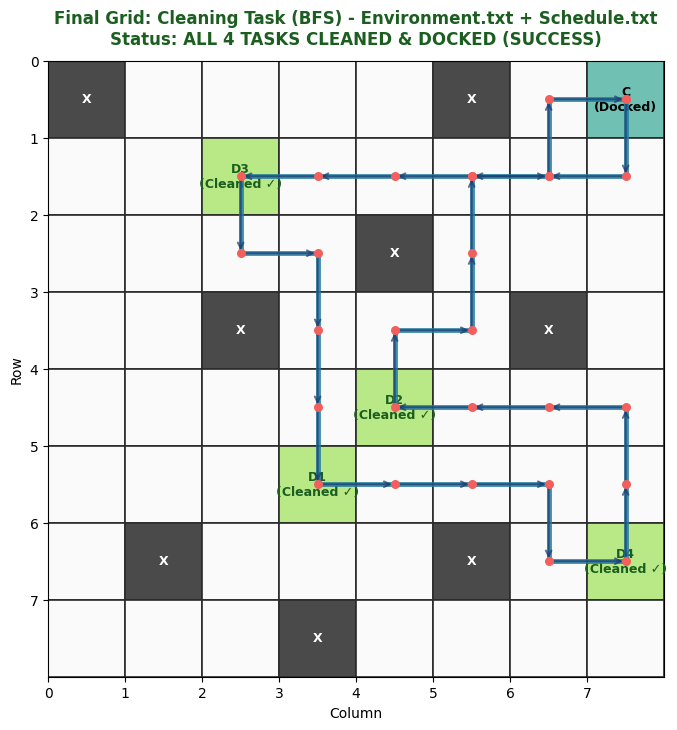

INTEGRATED ROBOT CLEANING EXECUTION (Algorithm: GBFS)
Starting Position: Charging Station at (0, 7)
Planned Sequence (from CSP): C -> D3 -> D1 -> D4 -> D2 -> C
---------------------------------------------------------------------------
Journey 1: (0, 7) -> D3 at (1, 2)
   Computed Path: [(0, 7), (1, 7), (1, 6), (1, 5), (1, 4), (1, 3), (1, 2)]
   Movements: 6 | Step Cost: 6 | Nodes Expanded: 7
   Simulation Action: Reached D3. Marked as CLEANED. [Cleaned: 1/4]

Journey 2: (1, 2) -> D1 at (5, 3)
   Computed Path: [(1, 2), (2, 2), (2, 3), (3, 3), (4, 3), (5, 3)]
   Movements: 5 | Step Cost: 5 | Nodes Expanded: 6
   Simulation Action: Reached D1. Marked as CLEANED. [Cleaned: 2/4]

Journey 3: (5, 3) -> D4 at (6, 7)
   Computed Path: [(5, 3), (5, 4), (5, 5), (5, 6), (6, 6), (6, 7)]
   Movements: 5 | Step Cost: 5 | Nodes Expanded: 8
   Simulation Action: Reached D4. Marked as CLEANED. [Cleaned: 3/4]

Journey 4: (6, 7) -> D2 at (4, 4)
   Computed Path: [(6, 7), (5, 7), (4, 7), (4, 6), (4, 5), 

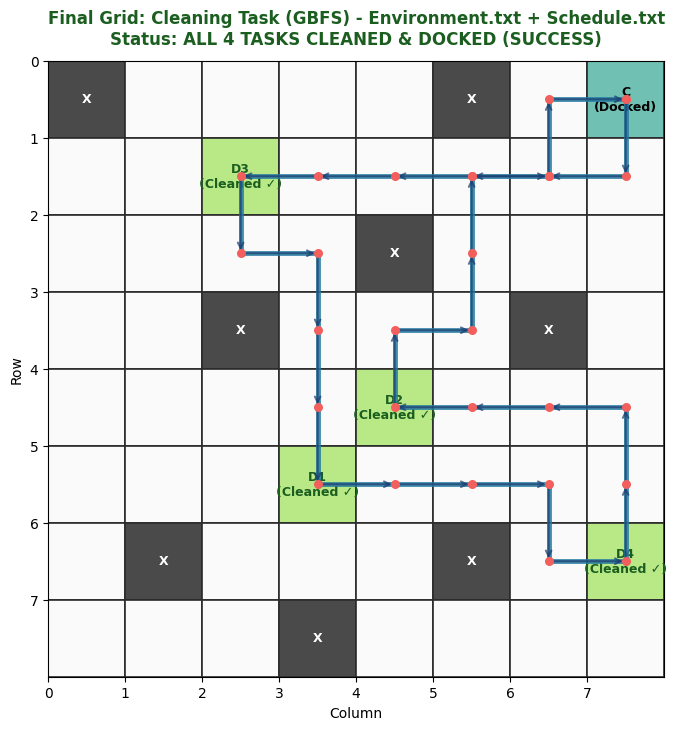

INTEGRATED ROBOT CLEANING EXECUTION (Algorithm: A*)
Starting Position: Charging Station at (0, 7)
Planned Sequence (from CSP): C -> D3 -> D1 -> D4 -> D2 -> C
---------------------------------------------------------------------------
Journey 1: (0, 7) -> D3 at (1, 2)
   Computed Path: [(0, 7), (1, 7), (1, 6), (1, 5), (1, 4), (1, 3), (1, 2)]
   Movements: 6 | Step Cost: 6 | Nodes Expanded: 8
   Simulation Action: Reached D3. Marked as CLEANED. [Cleaned: 1/4]

Journey 2: (1, 2) -> D1 at (5, 3)
   Computed Path: [(1, 2), (2, 2), (2, 3), (3, 3), (4, 3), (5, 3)]
   Movements: 5 | Step Cost: 5 | Nodes Expanded: 7
   Simulation Action: Reached D1. Marked as CLEANED. [Cleaned: 2/4]

Journey 3: (5, 3) -> D4 at (6, 7)
   Computed Path: [(5, 3), (5, 4), (5, 5), (5, 6), (6, 6), (6, 7)]
   Movements: 5 | Step Cost: 5 | Nodes Expanded: 9
   Simulation Action: Reached D4. Marked as CLEANED. [Cleaned: 3/4]

Journey 4: (6, 7) -> D2 at (4, 4)
   Computed Path: [(6, 7), (5, 7), (4, 7), (4, 6), (4, 5), (4

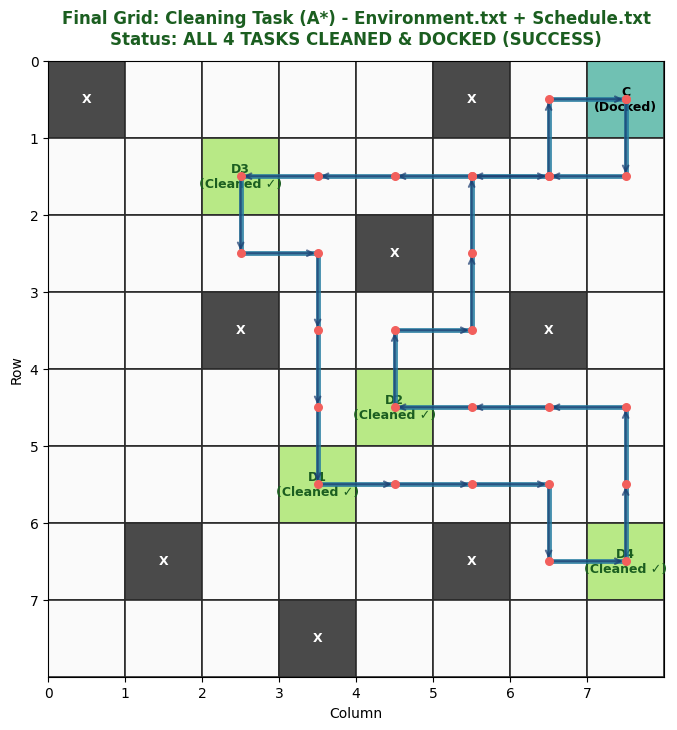

Algorithm comparison for Environment.txt + Schedule.txt
Algorithm   Movements   Total Cost  Nodes Expanded  Runtime (ms)  Cleaned   Status
-------------------------------------------------------------------------------------
BFS         28          28          164             0.497          4/4      SUCCESS
GBFS        28          28          35              0.180          4/4      SUCCESS
A*          28          28          49              0.229          4/4      SUCCESS

Resulting complete path of each algorithm (C -> D3 -> D1 -> D4 -> D2 -> C):
-------------------------------------------------------------------------------------
BFS  (states: 29, movements: 28)
   (0,7) -> (1,7) -> (1,6) -> (1,5) -> (1,4) -> (1,3) -> (1,2) -> (2,2) -> (2,3) -> (3,3) ->
   (4,3) -> (5,3) -> (5,4) -> (5,5) -> (5,6) -> (6,6) -> (6,7) -> (5,7) -> (4,7) -> (4,6) ->
   (4,5) -> (4,4) -> (3,4) -> (3,5) -> (2,5) -> (1,5) -> (1,6) -> (0,6) -> (0,7)
GBFS  (states: 29, movements: 28)
   (0,7) -> (1,7) -> (1,6)

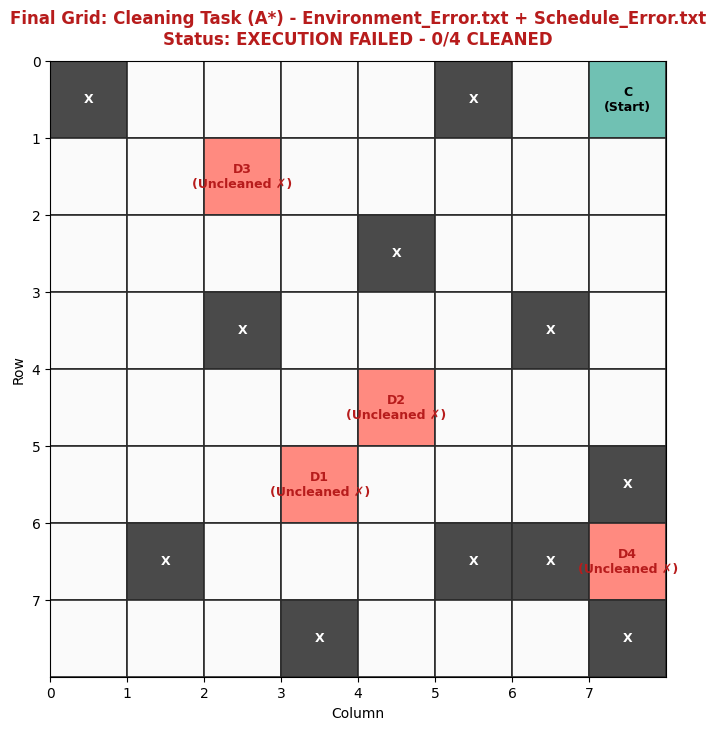


################################################################################
# RUN 3/3: Environment_Sample.txt + Schedule_Sample.txt  |  Integrated execution
################################################################################
Generated CSP Schedule Order: ['D2', 'D1', 'D3', 'D4']
INTEGRATED ROBOT CLEANING EXECUTION (Algorithm: BFS)
Starting Position: Charging Station at (0, 0)
Planned Sequence (from CSP): C -> D2 -> D1 -> D3 -> D4 -> C
---------------------------------------------------------------------------
Journey 1: (0, 0) -> D2 at (3, 7)
   Computed Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (3, 5), (3, 6), (3, 7)]
   Movements: 10 | Step Cost: 10 | Nodes Expanded: 48
   Simulation Action: Reached D2. Marked as CLEANED. [Cleaned: 1/4]

Journey 2: (3, 7) -> D1 at (0, 7)
   Computed Path: [(3, 7), (2, 7), (1, 7), (0, 7)]
   Movements: 3 | Step Cost: 3 | Nodes Expanded: 10
   Simulation Action: Reached D1. Marked as CLEANED. [Cleaned: 2/

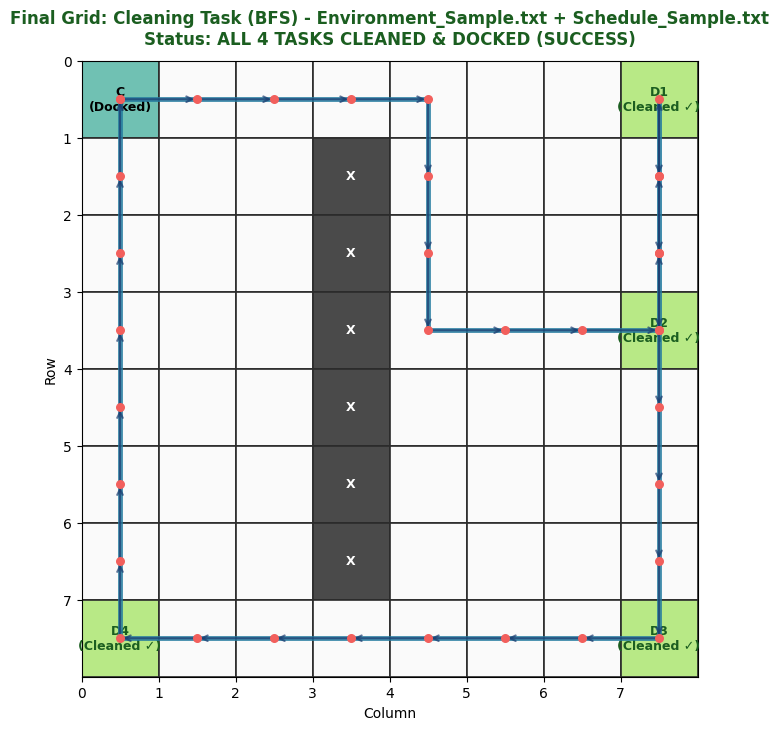

INTEGRATED ROBOT CLEANING EXECUTION (Algorithm: GBFS)
Starting Position: Charging Station at (0, 0)
Planned Sequence (from CSP): C -> D2 -> D1 -> D3 -> D4 -> C
---------------------------------------------------------------------------
Journey 1: (0, 0) -> D2 at (3, 7)
   Computed Path: [(0, 0), (1, 0), (2, 0), (3, 0), (3, 1), (3, 2), (2, 2), (1, 2), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (3, 5), (3, 6), (3, 7)]
   Movements: 16 | Step Cost: 16 | Nodes Expanded: 24
   Simulation Action: Reached D2. Marked as CLEANED. [Cleaned: 1/4]

Journey 2: (3, 7) -> D1 at (0, 7)
   Computed Path: [(3, 7), (2, 7), (1, 7), (0, 7)]
   Movements: 3 | Step Cost: 3 | Nodes Expanded: 4
   Simulation Action: Reached D1. Marked as CLEANED. [Cleaned: 2/4]

Journey 3: (0, 7) -> D3 at (7, 7)
   Computed Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (7, 7)]
   Movements: 7 | Step Cost: 7 | Nodes Expanded: 8
   Simulation Action: Reached D3. Marked as CLEANED. [Cleaned: 3/4]

Journey 4:

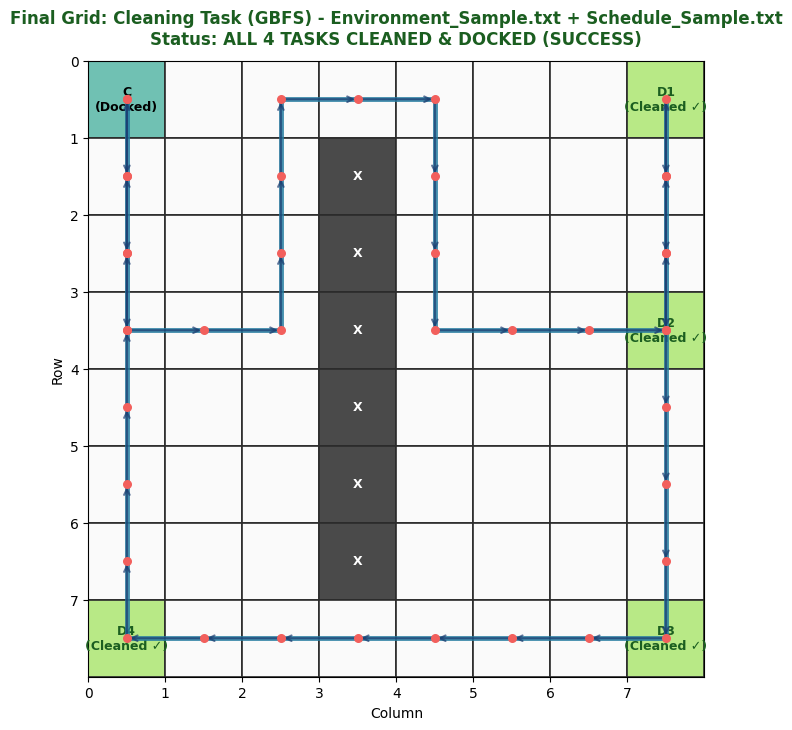

INTEGRATED ROBOT CLEANING EXECUTION (Algorithm: A*)
Starting Position: Charging Station at (0, 0)
Planned Sequence (from CSP): C -> D2 -> D1 -> D3 -> D4 -> C
---------------------------------------------------------------------------
Journey 1: (0, 0) -> D2 at (3, 7)
   Computed Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (3, 5), (3, 6), (3, 7)]
   Movements: 10 | Step Cost: 10 | Nodes Expanded: 29
   Simulation Action: Reached D2. Marked as CLEANED. [Cleaned: 1/4]

Journey 2: (3, 7) -> D1 at (0, 7)
   Computed Path: [(3, 7), (2, 7), (1, 7), (0, 7)]
   Movements: 3 | Step Cost: 3 | Nodes Expanded: 4
   Simulation Action: Reached D1. Marked as CLEANED. [Cleaned: 2/4]

Journey 3: (0, 7) -> D3 at (7, 7)
   Computed Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (7, 7)]
   Movements: 7 | Step Cost: 7 | Nodes Expanded: 8
   Simulation Action: Reached D3. Marked as CLEANED. [Cleaned: 3/4]

Journey 4: (7, 7) -> D4 at (7, 0)
   Computed Path: [(7, 7),

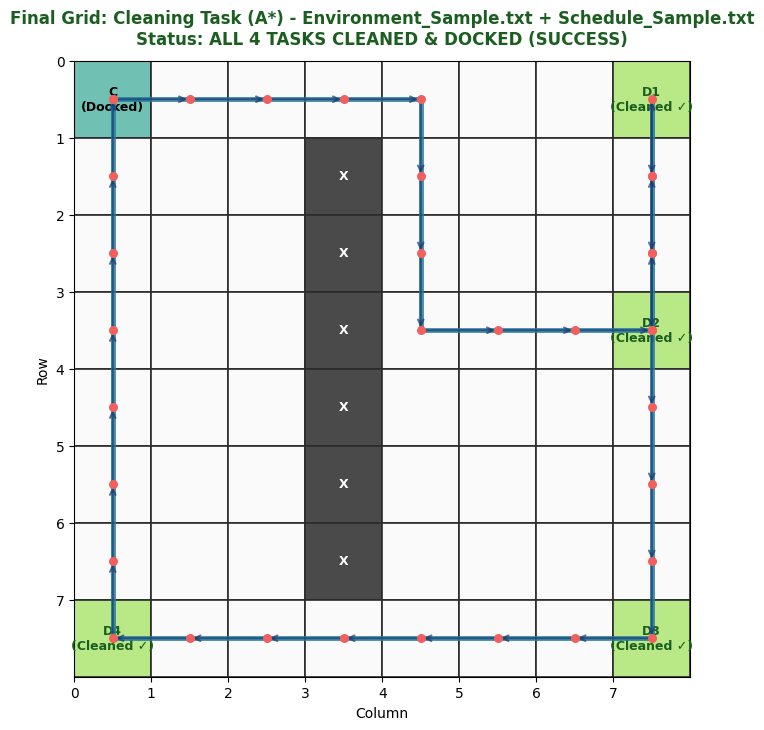

Algorithm comparison for Environment_Sample.txt + Schedule_Sample.txt
Algorithm   Movements   Total Cost  Nodes Expanded  Runtime (ms)  Cleaned   Status
-------------------------------------------------------------------------------------
BFS         34          34          144             0.408          4/4      SUCCESS
GBFS        40          40          52              0.221          4/4      SUCCESS
A*          34          34          57              0.306          4/4      SUCCESS

Resulting complete path of each algorithm (C -> D2 -> D1 -> D3 -> D4 -> C):
-------------------------------------------------------------------------------------
BFS  (states: 35, movements: 34)
   (0,0) -> (0,1) -> (0,2) -> (0,3) -> (0,4) -> (1,4) -> (2,4) -> (3,4) -> (3,5) -> (3,6) ->
   (3,7) -> (2,7) -> (1,7) -> (0,7) -> (1,7) -> (2,7) -> (3,7) -> (4,7) -> (5,7) -> (6,7) ->
   (7,7) -> (7,6) -> (7,5) -> (7,4) -> (7,3) -> (7,2) -> (7,1) -> (7,0) -> (6,0) -> (5,0) ->
   (4,0) -> (3,0) -> (2,0) -> (1,0

In [74]:
import textwrap

# Algorithms whose full journey log + final grid are shown (set to ["A*"] to show only A*)
DETAILED_ALGOS = list(ALGO_NAMES)


def _fmt_path(path):
    """(0,7) -> (1,7) -> ... ; None/empty -> 'no path'."""
    return " -> ".join(f"({r},{c})" for r, c in path) if path else "no path"


def integrated_execution(run):
    """Executes the CSP schedule of ONE run with every algorithm in DETAILED_ALGOS (journey log + final grid)
    and then compares BFS/GBFS/A* in one table, followed by the complete path of each algorithm."""
    run_header(run, "Integrated execution")
    grid = run["grid"]
    run["exec"] = {}
    if grid is None:
        print(f"[SKIPPED] Environment '{run['env_file']}' could not be loaded - nothing to execute.")
        return
    charging = grid["charging_station"]
    if charging is None:
        print("[STOP] The environment has no charging station - the robot cannot run. Reporting failure:\n")
        execute_schedule(grid, None, None, algorithm="A*")
        return
    if not run["env_ok"]:
        print("[NOTE] Environment validation failed; the robot is still run on purpose so that "
              "execute_schedule's own failure detection is demonstrated.\n")

    order = run["order"]
    if order is not None:
        print(f"Generated CSP Schedule Order: {order}")
    else:
        print(f"No feasible CSP schedule (status = {run['csp_status']}) -> reporting execution failure.\n")

    # No schedule: the failure report is identical for every algorithm, so show it once (with A*)
    algos_to_show = DETAILED_ALGOS if order is not None else ["A*"]

    # Execute with each algorithm, then draw the final grid from what the robot really reached
    for algo in algos_to_show:
        report = {}
        path, cost, success = execute_schedule(grid, charging, order, algorithm=algo, report=report)
        visualize_final_grid(grid, path, report["cleaned"], success=success,
                             algorithm=algo, source=run["label"])

    if order is None:
        return

    # Compare all 3 algorithms on the complete integrated schedule
    print(f"Algorithm comparison for {run['label']}")
    print(f"{'Algorithm':<12}{'Movements':<12}{'Total Cost':<12}{'Nodes Expanded':<16}{'Runtime (ms)':<14}{'Cleaned':<10}{'Status'}")
    print("-" * 85)
    paths = {}
    for algo in ALGO_NAMES:
        rep = {}
        p, c, ok = execute_schedule(grid, charging, order, algorithm=algo, verbose=False, report=rep)
        paths[algo] = p
        run["exec"][algo] = {"success": ok, "cost": c, "movements": rep["movements"],
                             "nodes": rep["nodes_expanded"], "cleaned": len(rep["cleaned"]), "path": p}
        print(f"{algo:<12}{rep['movements']:<12}{c:<12}{rep['nodes_expanded']:<16}{rep['runtime_ms']:<14.3f}"
              f"{len(rep['cleaned']):>2}/{len(grid['dirty_locations']):<7}{'SUCCESS' if ok else 'FAILED'}")

    # Resulting complete path (charging station -> all dirty locations in CSP order -> charging station)
    print("\nResulting complete path of each algorithm (C -> " + " -> ".join(order) + " -> C):")
    print("-" * 85)
    for algo in ALGO_NAMES:
        p = paths[algo]
        print(f"{algo}  (states: {len(p) if p else 0}, movements: {run['exec'][algo]['movements']})")
        print(textwrap.fill(_fmt_path(p), width=95, initial_indent="   ", subsequent_indent="   ",
                            break_long_words=False, break_on_hyphens=False))
    if len({tuple(p) if p else None for p in paths.values()}) == 1:
        print("-> All three algorithms followed exactly the SAME complete path.")
    else:
        best = min(run["exec"][a]["cost"] for a in ALGO_NAMES)
        worse = [a for a in ALGO_NAMES if run["exec"][a]["cost"] > best]
        print(f"-> Complete paths DIFFER. Optimal total cost = {best}; "
              f"longer journey: {', '.join(worse) if worse else 'none (equal-cost alternatives)'}.")


for run in iter_runs():
    integrated_execution(run)

## **15. Summary of All Uploaded Pairs**

Every uploaded Environment/Schedule pair has already been taken through the complete pipeline in Sections 5-14:
load environment -> validate -> load schedule -> validate -> CSP -> verify -> `execute_schedule` -> final grid.
Success runs and failure runs (invalid environment, invalid or infeasible schedule, unreachable dirty location) therefore all show their own results in every section.

The table below puts all pairs side by side. For failure cases the important point is that `execute_schedule` reports **FAILURE** and never claims that the cleaning was completed.

In [75]:
def summarize_runs():
    if not RUNS:
        print("[NO INPUT] Nothing to summarise.")
        return
    print("=" * 118)
    print(f"SUMMARY OF {len(RUNS)} ENVIRONMENT/SCHEDULE PAIR(S)")
    print("=" * 118)
    ew = max(len(r["env_file"]) for r in RUNS) + 2
    sw = max(len(r["sched_file"]) for r in RUNS) + 2
    print(f"{'Run':<5}{'Environment':<{ew}}{'Schedule':<{sw}}{'Env':<9}{'Sched':<9}{'CSP status':<15}"
          f"{'BFS':<11}{'GBFS':<11}{'A*':<11}Outcome")
    print("-" * 118)
    for r in RUNS:
        def cell(algo):
            e = r["exec"].get(algo)
            return "-" if e is None else (f"OK/{e['cost']}" if e["success"] else "FAILED")
        env_txt = "valid" if r["env_ok"] else "INVALID"
        sch_txt = "valid" if r["sched_ok"] else ("INVALID" if r["csp_ready"] else "n/a")
        astar = r["exec"].get("A*")
        outcome = ("ALL CLEANED + DOCKED" if (astar and astar["success"])
                   else "FAILURE REPORTED (no false success)")
        print(f"{r['index']:<5}{r['env_file']:<{ew}}{r['sched_file']:<{sw}}{env_txt:<9}{sch_txt:<9}{r['csp_status']:<15}"
              f"{cell('BFS'):<11}{cell('GBFS'):<11}{cell('A*'):<11}{outcome}")
    print("-" * 118)
    print("Env/Sched = validation result | BFS/GBFS/A* = 'OK/<total cost>' if every dirty location was cleaned "
          "and the robot docked, else FAILED.")
    if UNPAIRED_FILES:
        print("\n[WARNING] Ignored (unpaired) files:", ", ".join(UNPAIRED_FILES))


summarize_runs()

SUMMARY OF 3 ENVIRONMENT/SCHEDULE PAIR(S)
Run  Environment             Schedule             Env      Sched    CSP status     BFS        GBFS       A*         Outcome
----------------------------------------------------------------------------------------------------------------------
1    Environment.txt         Schedule.txt         valid    valid    SOLVED         OK/28      OK/28      OK/28      ALL CLEANED + DOCKED
2    Environment_Error.txt   Schedule_Error.txt   INVALID  valid    INFEASIBLE     -          -          -          FAILURE REPORTED (no false success)
3    Environment_Sample.txt  Schedule_Sample.txt  valid    valid    SOLVED         OK/34      OK/40      OK/34      ALL CLEANED + DOCKED
----------------------------------------------------------------------------------------------------------------------
Env/Sched = validation result | BFS/GBFS/A* = 'OK/<total cost>' if every dirty location was cleaned and the robot docked, else FAILED.


### **16. Algorithmic Discussion & Performance**
*(The exact figures are produced by the code in Sections 8.2 (8.2.3) and 14. The statements below are deliberately qualitative so that they always agree with the measured results.)*

1. **Search Component:**
   - **BFS:** Explores exhaustively, providing a baseline for the minimum possible path cost. It serves as our correctness benchmark (ground truth for optimality).
   - **GBFS:** Often expands very few nodes when the straight line to the goal is open, but it ranks nodes by $h(n)$ only, so it **can** produce sub-optimal paths when a goal lies behind a wall or pocket. On a particular map it may happen to be optimal for every pair; the optimal-path rate (8.2.2) shows it is *not guaranteed*.
   - **A\* Search:** Matches BFS's optimal path cost while expanding substantially fewer nodes; the measured reduction for the loaded environment is reported in 8.2.3. Because Manhattan distance is admissible and consistent, optimality is guaranteed.
2. **CSP Component:**
   - **Node consistency** applies the unary latest-slot bounds once, up front; **MRV** with the **Degree** tie-breaker picks the most constrained task first; **LCV** orders slots to keep options open; **Forward Checking** (slot-exclusivity and precedence) detects domain wipe-outs immediately. `is_consistent` re-checks all three constraint types on every assignment.
   - Infeasible problems are explained by `diagnose_infeasibility` (too few slots, a precedence cycle, an empty time window or an over-subscribed deadline) instead of a fixed message.
3. **Integration:**
   - `execute_schedule` marks a location as cleaned only after a path to it has actually been found, reports the *planned* and the *visited* sequence separately, and requires every dirty location to be cleaned **and** the robot to be docked before it reports success.
   - The solver never runs on an invalid schedule file; the robot never runs on a missing schedule.

---